# Experiment 4 — Market Indicators and S&P 500 Direction Prediction

**Objective**  
Evaluate whether market indicators and price-action features improve the prediction of the S&P 500’s next-trading-day direction.

**Prediction target**  
- `1` — the next trading day has a positive S&P 500 return.
- `0` — the next trading day has a zero or negative S&P 500 return.

**Inputs examined**  
Historical S&P 500 prices and volume, VIX, NASDAQ returns, and the CBOE SPX + SPW put/call volume ratio, followed by engineered price-action features.

**Workflow**  
1. Collect and align the source datasets.
2. Engineer features and establish baseline model performance.
3. Compare feature sets, model types, thresholds, and class-weight settings.
4. Evaluate model consistency and probability quality using chronological validation.

> **Execution note:** Run the notebook from top to bottom. File paths are relative to the notebook location, and later cells depend on variables created earlier.


## 1. Imports and environment

Import the libraries used throughout the notebook and configure Pandas display settings.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Financial market data
import yfinance as yf

# Data visualization
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

## 2. Data collection and preparation

### 2.1 Load the original S&P 500 dataset

The existing `sp500.csv` file should be available in `data/raw/` before running the next cell.

In [2]:
from pathlib import Path

# Load original S&P 500 dataset
df = pd.read_csv("../data/raw/sp500.csv")

# Standardize dates
def clean_date(value):
    date = pd.Timestamp(value)

    if date.tzinfo is not None:
        date = date.tz_convert(
            "America/New_York"
        ).tz_localize(None)

    return date.normalize()

df["Date"] = df["Date"].apply(clean_date)

# Sort chronologically
df = df.sort_values("Date").reset_index(drop=True)

# Inspect dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
display(df.isnull().sum())

Dataset shape: (2514, 8)

First five rows:


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2016-11-21,2186.429932,2198.699951,2186.429932,2198.179932,3611500000,0.0,0.0
1,2016-11-22,2201.560059,2204.800049,2194.510010,2202.939941,3960520000,0.0,0.0
2,2016-11-23,2198.550049,2204.719971,2194.510010,2204.719971,3419850000,0.0,0.0
3,2016-11-25,2206.270020,2213.350098,2206.270020,2213.350098,1584590000,0.0,0.0
4,2016-11-28,2210.209961,2211.139893,2200.360107,2201.719971,3515100000,0.0,0.0



Missing values:


Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64

### 2.2 Download VIX and NASDAQ indicators

Download daily VIX and NASDAQ data and standardize their dates before saving the combined file.

In [3]:
# Tickers we want to download
tickers = {
    "^VIX": "VIX",
    "^IXIC": "NASDAQ"
}

market_data = {}

for ticker_symbol, column_name in tickers.items():

    print(f"Downloading {column_name}...")

    ticker = yf.Ticker(ticker_symbol)

    data = ticker.history(
        period="10y",
        interval="1d",
        auto_adjust=True
    )

    if data.empty:
        raise ValueError(f"No data downloaded for {ticker_symbol}")

    # Standardize dates to New York time
    dates = pd.DatetimeIndex(data.index)

    if dates.tz is not None:
        dates = dates.tz_convert(
            "America/New_York"
        ).tz_localize(None)

    data.index = dates.normalize()

    # Store closing prices
    market_data[column_name] = data["Close"]


# Combine both datasets
market_data = pd.concat(market_data.values(), axis=1)

market_data.index.name = "Date"

# Inspect results
print("\nMarket data shape:", market_data.shape)

display(market_data.head())

print("\nMissing values:")
display(market_data.isnull().sum())


Market data shape: (2516, 2)


,Close,Close
Date,,
2016-11-25,12.34,NaN
2016-11-28,13.15,5368.810059
2016-11-29,12.90,5379.919922
2016-11-30,13.33,5323.680176
2016-12-01,14.07,5251.109863



Missing values:


Close    0
Close    3
dtype: int64

In [4]:
# Give the downloaded columns meaningful names
market_data.columns = ["VIX", "NASDAQ"]

market_data.index.name = "Date"

# Save the corrected dataset
market_data.to_csv("../data/raw/market_indicators.csv")

display(market_data.head())
print(market_data.isnull().sum())

,VIX,NASDAQ
Date,,
2016-11-25,12.34,NaN
2016-11-28,13.15,5368.810059
2016-11-29,12.90,5379.919922
2016-11-30,13.33,5323.680176
2016-12-01,14.07,5251.109863


VIX       0
NASDAQ    3
dtype: int64


### 2.3 Inspect the CBOE daily statistics tables

The next cells inspect the CBOE daily page and compare candidate table positions for the SPX + SPW call/put volume data. The downloaded daily ratio dataset is loaded below.

In [5]:
import requests
from io import StringIO

# Test a known trading date
test_date = "2024-01-02"

# CBOE daily market statistics URL
url = (
    "https://www.cboe.com/markets/us/options/"
    f"market-statistics/daily?dt={test_date}"
)

print(f"Downloading CBOE data for {test_date}...")

# Request the webpage
response = requests.get(
    url,
    headers={"User-Agent": "Mozilla/5.0"},
    timeout=30
)

response.raise_for_status()

# Extract HTML tables
tables = pd.read_html(StringIO(response.text))

print("Tables found:", len(tables))

# Inspect available tables and their columns
for i, table in enumerate(tables):
    print(
        f"\nTable {i}:",
        "Shape:", table.shape,
        "| Columns:", table.columns.tolist()
    )

Tables found: 14

Table 0: Shape: (13, 2) | Columns: ['Ratios', 'Value']

Table 1: Shape: (2, 4) | Columns: [('SUM OF ALL PRODUCTS', 'Name'), ('SUM OF ALL PRODUCTS', 'Call'), ('SUM OF ALL PRODUCTS', 'Put'), ('SUM OF ALL PRODUCTS', 'Total')]

Table 2: Shape: (2, 4) | Columns: [('INDEX OPTIONS', 'Name'), ('INDEX OPTIONS', 'Call'), ('INDEX OPTIONS', 'Put'), ('INDEX OPTIONS', 'Total')]

Table 3: Shape: (2, 4) | Columns: [('EXCHANGE TRADED PRODUCTS', 'Name'), ('EXCHANGE TRADED PRODUCTS', 'Call'), ('EXCHANGE TRADED PRODUCTS', 'Put'), ('EXCHANGE TRADED PRODUCTS', 'Total')]

Table 4: Shape: (2, 4) | Columns: [('EQUITY OPTIONS', 'Name'), ('EQUITY OPTIONS', 'Call'), ('EQUITY OPTIONS', 'Put'), ('EQUITY OPTIONS', 'Total')]

Table 5: Shape: (2, 4) | Columns: [('CBOE VOLATILITY INDEX (VIX)', 'Name'), ('CBOE VOLATILITY INDEX (VIX)', 'Call'), ('CBOE VOLATILITY INDEX (VIX)', 'Put'), ('CBOE VOLATILITY INDEX (VIX)', 'Total')]

Table 6: Shape: (2, 4) | Columns: [('SPX + SPXW', 'Name'), ('SPX + SPXW', 'Cal

In [6]:
# Candidate at pandas table index 5 (sixth HTML table)
spx_options_table = tables[5].copy()

# Flatten the MultiIndex column headers
if isinstance(spx_options_table.columns, pd.MultiIndex):
    spx_options_table.columns = [
        str(col[-1]).strip()
        for col in spx_options_table.columns
    ]
else:
    spx_options_table.columns = [
        str(col).strip()
        for col in spx_options_table.columns
    ]

print("Columns:", spx_options_table.columns.tolist())

# Get the VOLUME row, not open interest
volume_row = spx_options_table[
    spx_options_table["Name"].str.upper() == "VOLUME"
].iloc[0]

# Extract call and put volume
call_volume = float(volume_row["Call"])
put_volume = float(volume_row["Put"])

# Calculate Put/Call Ratio
put_call_ratio = put_volume / call_volume

print("\nDate:", test_date)
print("Call Volume:", call_volume)
print("Put Volume:", put_volume)
print("Put/Call Ratio:", round(put_call_ratio, 4))

Columns: ['Name', 'Call', 'Put', 'Total']

Date: 2024-01-02
Call Volume: 537111.0
Put Volume: 145124.0
Put/Call Ratio: 0.2702


In [7]:
# Candidate at pandas table index 6 (seventh HTML table)
spx_options_table = tables[6].copy()

# Flatten column headers
if isinstance(spx_options_table.columns, pd.MultiIndex):
    spx_options_table.columns = [
        str(col[-1]).strip()
        for col in spx_options_table.columns
    ]
else:
    spx_options_table.columns = [
        str(col).strip()
        for col in spx_options_table.columns
    ]

# Extract VOLUME row
volume_row = spx_options_table[
    spx_options_table["Name"].str.upper() == "VOLUME"
].iloc[0]

call_volume = float(volume_row["Call"])
put_volume = float(volume_row["Put"])

# Calculate ratio
put_call_ratio = put_volume / call_volume

print("Date:", test_date)
print("Call Volume:", call_volume)
print("Put Volume:", put_volume)
print("Put/Call Ratio:", round(put_call_ratio, 4))

Date: 2024-01-02
Call Volume: 1317943.0
Put Volume: 1786015.0
Put/Call Ratio: 1.3552


### 2.4 Load the completed daily Put/Call Ratio dataset

Use the collected daily observations rather than re-downloading the full historical series every time the modeling section is run.

In [8]:
# Load the completed Put/Call Ratio dataset
put_call_data = pd.read_csv(
    "../data/raw/put_call_ratio_daily.csv"
)

put_call_data["Date"] = pd.to_datetime(
    put_call_data["Date"]
)

print("Dataset shape:", put_call_data.shape)

print("\nDate range:")
print(
    put_call_data["Date"].min(),
    "to",
    put_call_data["Date"].max()
)

print("\nMissing values:")
display(put_call_data.isnull().sum())

print("\nFirst five rows:")
display(put_call_data.head())

Dataset shape: (1792, 4)

Date range:
2019-10-07 00:00:00 to 2026-11-20 00:00:00

Missing values:


Date              0
Call_Volume       0
Put_Volume        0
Put_Call_Ratio    0
dtype: int64


First five rows:


,Date,Call_Volume,Put_Volume,Put_Call_Ratio
0,2019-10-07,403679.0,705496.0,1.747666
1,2019-10-08,441902.0,755753.0,1.710228
2,2019-10-09,325805.0,748860.0,2.298491
3,2019-10-10,458875.0,788029.0,1.717306
4,2019-10-11,627474.0,1112661.0,1.773238


## 3. Merge and validate the market datasets

The first merge is inspected for missing NASDAQ changes. The following alignment step recalculates daily changes on S&P 500 trading sessions and rebuilds the merged dataset.

In [9]:
# Load VIX and NASDAQ data
market_df = pd.read_csv("../data/raw/market_indicators.csv")

# Load S&P 500 data
sp500_df = df.copy()

# Load Put/Call Ratio data
put_call_df = pd.read_csv(
    "../data/raw/put_call_ratio_daily.csv"
)

# Standardize all dates
sp500_df["Date"] = pd.to_datetime(
    sp500_df["Date"]
).dt.normalize()

market_df["Date"] = pd.to_datetime(
    market_df["Date"]
).dt.normalize()

put_call_df["Date"] = pd.to_datetime(
    put_call_df["Date"]
).dt.normalize()


# Calculate new market features
market_df["VIX_Change"] = market_df["VIX"].pct_change(
    fill_method=None
)

market_df["NASDAQ_Return"] = market_df["NASDAQ"].pct_change(
    fill_method=None
)


# Merge S&P 500 with VIX and NASDAQ
df_exp4 = sp500_df.merge(
    market_df,
    on="Date",
    how="inner",
    validate="one_to_one"
)

# Merge Put/Call Ratio
df_exp4 = df_exp4.merge(
    put_call_df[[
        "Date",
        "Put_Call_Ratio"
    ]],
    on="Date",
    how="inner",
    validate="one_to_one"
)

# Sort chronologically
df_exp4 = df_exp4.sort_values(
    "Date"
).reset_index(drop=True)


# Inspect combined dataset
print("Combined dataset shape:", df_exp4.shape)

print("\nDate range:")
print(df_exp4["Date"].min(), "to", df_exp4["Date"].max())

print("\nMissing values:")
display(df_exp4.isnull().sum())

print("\nFirst five rows:")
display(df_exp4.head())

Combined dataset shape: (1792, 13)

Date range:
2019-10-07 00:00:00 to 2026-11-20 00:00:00

Missing values:


Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Dividends         0
Stock Splits      0
VIX               0
NASDAQ            0
VIX_Change        0
NASDAQ_Return     2
Put_Call_Ratio    0
dtype: int64


First five rows:


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,VIX,NASDAQ,VIX_Change,NASDAQ_Return,Put_Call_Ratio
0,2019-10-07,2944.229980,2959.750000,2935.679932,2938.790039,2959050000,0.0,0.0,17.860001,7956.290039,0.048122,-0.003280,1.747666
1,2019-10-08,2920.399902,2925.469971,2892.659912,2893.060059,3370700000,0.0,0.0,20.280001,7823.779785,0.135498,-0.016655,1.710228
2,2019-10-09,2911.100098,2929.320068,2907.409912,2919.399902,2735350000,0.0,0.0,18.639999,7903.740234,-0.080868,0.010220,2.298491
3,2019-10-10,2918.550049,2948.459961,2917.120117,2938.129883,3234400000,0.0,0.0,17.570000,7950.779785,-0.057403,0.005952,1.717306
4,2019-10-11,2963.070068,2993.280029,2963.070068,2970.270020,3581320000,0.0,0.0,15.580000,8057.040039,-0.113261,0.013365,1.773238


In [10]:
# Find rows with missing NASDAQ returns
missing_rows = df_exp4[
    df_exp4["NASDAQ_Return"].isna()
][["Date", "NASDAQ", "NASDAQ_Return"]]

display(missing_rows)

,Date,NASDAQ,NASDAQ_Return
1666,2026-05-26,26656.179688,NaN
1738,2026-09-08,26421.410156,NaN


In [11]:
# Get actual S&P 500 trading dates
sp500_dates = set(sp500_df["Date"])

# Keep only dates when the S&P 500 was trading
market_trading_days = market_df[
    market_df["Date"].isin(sp500_dates)
].copy()

market_trading_days = market_trading_days.sort_values(
    "Date"
).reset_index(drop=True)


# Recalculate daily changes using consecutive trading sessions
market_trading_days["VIX_Change"] = (
    market_trading_days["VIX"].pct_change(fill_method=None)
)

market_trading_days["NASDAQ_Return"] = (
    market_trading_days["NASDAQ"].pct_change(fill_method=None)
)


# Rebuild combined dataset
df_exp4 = sp500_df.merge(
    market_trading_days,
    on="Date",
    how="inner",
    validate="one_to_one"
)

df_exp4 = df_exp4.merge(
    put_call_df[["Date", "Put_Call_Ratio"]],
    on="Date",
    how="inner",
    validate="one_to_one"
)

df_exp4 = df_exp4.sort_values(
    "Date"
).reset_index(drop=True)


# Check results
print("Combined dataset shape:", df_exp4.shape)

print("\nMissing values:")
display(df_exp4.isnull().sum())

print("\nNASDAQ return on previously affected dates:")
display(
    df_exp4[
        df_exp4["Date"].isin([
            "2026-05-26",
            "2026-09-08"
        ])
    ][["Date", "NASDAQ", "NASDAQ_Return"]]
)

Combined dataset shape: (1792, 13)

Missing values:


Date              0
Open              0
High              0
Low               0
Close             0
Volume            0
Dividends         0
Stock Splits      0
VIX               0
NASDAQ            0
VIX_Change        0
NASDAQ_Return     0
Put_Call_Ratio    0
dtype: int64


NASDAQ return on previously affected dates:


,Date,NASDAQ,NASDAQ_Return


## 4. Feature engineering and prediction target

Create technical indicators from S&P 500 price history and define the next-session direction label.

In [12]:
# Daily S&P 500 return
df_exp4["Daily_Return"] = df_exp4["Close"].pct_change(
    fill_method=None
)

# Moving averages
df_exp4["MA5"] = df_exp4["Close"].rolling(5).mean()
df_exp4["MA10"] = df_exp4["Close"].rolling(10).mean()
df_exp4["MA20"] = df_exp4["Close"].rolling(20).mean()

# Moving average ratios
df_exp4["MA5_Ratio"] = (df_exp4["Close"] / df_exp4["MA5"]) - 1
df_exp4["MA10_Ratio"] = (df_exp4["Close"] / df_exp4["MA10"]) - 1
df_exp4["MA20_Ratio"] = (df_exp4["Close"] / df_exp4["MA20"]) - 1

# Momentum
df_exp4["Momentum5"] = df_exp4["Close"].pct_change(5)
df_exp4["Momentum10"] = df_exp4["Close"].pct_change(10)

# Volatility
df_exp4["Volatility10"] = df_exp4["Daily_Return"].rolling(10).std()
df_exp4["Volatility20"] = df_exp4["Daily_Return"].rolling(20).std()

# RSI
delta = df_exp4["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(14).mean()
avg_loss = loss.rolling(14).mean()

rs = avg_gain / avg_loss

df_exp4["RSI"] = 100 - (100 / (1 + rs))


# Create next-day prediction target
df_exp4["Next_Day_Return"] = (
    df_exp4["Daily_Return"].shift(-1)
)

df_exp4["Target"] = np.where(
    df_exp4["Next_Day_Return"].notna(),
    (df_exp4["Next_Day_Return"] > 0).astype(int),
    np.nan
)


# Define all 13 features
features_exp4 = [
    "Daily_Return",
    "MA5_Ratio",
    "MA10_Ratio",
    "MA20_Ratio",
    "Momentum5",
    "Momentum10",
    "Volatility10",
    "Volatility20",
    "RSI",
    "VIX",
    "VIX_Change",
    "NASDAQ_Return",
    "Put_Call_Ratio"
]


# Remove rows with incomplete features or targets
df_exp4 = df_exp4.dropna(
    subset=features_exp4 + ["Target"]
).copy()

df_exp4["Target"] = df_exp4["Target"].astype(int)


# Prepare X and y
X_exp4 = df_exp4[features_exp4]
y_exp4 = df_exp4["Target"]


print("Final dataset shape:", df_exp4.shape)
print("Number of features:", len(features_exp4))

print("\nMissing values:")
display(df_exp4[features_exp4 + ["Target"]].isnull().sum())

print("\nTarget distribution:")
display(y_exp4.value_counts().rename(
    index={0: "Down/flat", 1: "Up"}
))

print("\nFirst five rows:")
display(df_exp4[["Date"] + features_exp4 + ["Target"]].head())

Final dataset shape: (1771, 27)
Number of features: 13

Missing values:


Daily_Return      0
MA5_Ratio         0
MA10_Ratio        0
MA20_Ratio        0
Momentum5         0
Momentum10        0
Volatility10      0
Volatility20      0
RSI               0
VIX               0
VIX_Change        0
NASDAQ_Return     0
Put_Call_Ratio    0
Target            0
dtype: int64


Target distribution:


Target
Up           959
Down/flat    812
Name: count, dtype: int64


First five rows:


,Date,Daily_Return,MA5_Ratio,MA10_Ratio,MA20_Ratio,Momentum5,Momentum10,Volatility10,Volatility20,RSI,VIX,VIX_Change,NASDAQ_Return,Put_Call_Ratio,Target
20,2019-11-04,0.003704,0.008185,0.014619,0.026049,0.012782,0.023797,0.004000,0.006288,75.332827,12.83,0.043089,0.005580,1.177491,0
21,2019-11-05,-0.001186,0.004507,0.010796,0.021740,0.012424,0.026245,0.003664,0.004774,76.430017,13.10,0.021044,0.000175,1.617474,1
22,2019-11-06,0.000702,0.003245,0.009109,0.019791,0.009850,0.024050,0.003711,0.004580,75.499828,12.62,-0.036641,-0.002851,1.699630,1
23,2019-11-07,0.002730,0.002870,0.009385,0.020090,0.015677,0.024878,0.003708,0.004493,82.727205,12.73,0.008716,0.002840,0.985818,1
24,2019-11-08,0.002561,0.003730,0.009640,0.020630,0.008533,0.023335,0.003666,0.004027,81.154473,12.07,-0.051846,0.004836,1.888700,0


In [13]:
# Original 9 technical features
features_original = [
    "Daily_Return",
    "MA5_Ratio",
    "MA10_Ratio",
    "MA20_Ratio",
    "Momentum5",
    "Momentum10",
    "Volatility10",
    "Volatility20",
    "RSI"
]

# Expanded 13 features
features_expanded = features_original + [
    "VIX",
    "VIX_Change",
    "NASDAQ_Return",
    "Put_Call_Ratio"
]


# Prepare datasets using the SAME observations
X_original = df_exp4[features_original].copy()
X_expanded = df_exp4[features_expanded].copy()
y = df_exp4["Target"].copy()


# Chronological 80/20 split
split_index = int(len(df_exp4) * 0.8)

# Original features
X_train_original = X_original.iloc[:split_index]
X_test_original = X_original.iloc[split_index:]

# Expanded features
X_train_expanded = X_expanded.iloc[:split_index]
X_test_expanded = X_expanded.iloc[split_index:]

# Shared target
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]


# Inspect split
print("Original feature count:", len(features_original))
print("Expanded feature count:", len(features_expanded))

print("\nTraining observations:", len(y_train))
print("Testing observations:", len(y_test))

print("\nTraining dates:")
print(df_exp4["Date"].iloc[0], "to",
      df_exp4["Date"].iloc[split_index - 1])

print("\nTesting dates:")
print(df_exp4["Date"].iloc[split_index], "to",
      df_exp4["Date"].iloc[-1])

# Baseline
baseline_accuracy = (y_test == 1).mean()

print("\nAlways-UP baseline accuracy:",
      round(baseline_accuracy, 4))

Original feature count: 9
Expanded feature count: 13

Training observations: 1416
Testing observations: 355

Training dates:
2019-11-04 00:00:00 to 2025-06-24 00:00:00

Testing dates:
2025-06-25 00:00:00 to 2026-11-19 00:00:00

Always-UP baseline accuracy: 0.5352


## 5. Initial model evaluation

### 5.1 Holdout comparison and chronological cross-validation

Establish baseline performance and compare Logistic Regression, Random Forest, and SVM using the original technical features and the expanded market-indicator set.

In [14]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


# Define our models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        class_weight="balanced"
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced"
        ))
    ])
}


# Compare original and expanded feature sets
datasets = {
    "9 Features": (
        X_train_original,
        X_test_original
    ),
    "13 Features": (
        X_train_expanded,
        X_test_expanded
    )
}


results = []
fitted_models = {}


# Train and evaluate all six models
for feature_set, (X_train, X_test) in datasets.items():

    for model_name, model in models.items():

        fitted_model = clone(model)

        # Train
        fitted_model.fit(X_train, y_train)

        # Predict
        predictions = fitted_model.predict(X_test)

        # Calculate metrics
        results.append({
            "Feature Set": feature_set,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test, predictions, zero_division=0
            )
        })

        fitted_models[(feature_set, model_name)] = fitted_model

        print(f"\n{feature_set} - {model_name}")
        print("Confusion Matrix:")
        print(confusion_matrix(y_test, predictions))


# Display comparison
holdout_results = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")

display(
    holdout_results
    .set_index(["Model", "Feature Set"])
    .style.format("{:.4f}")
)

print("\nAlways-UP baseline:", round(baseline_accuracy, 4))


9 Features - Logistic Regression
Confusion Matrix:
[[  4 161]
 [  5 185]]

9 Features - Random Forest
Confusion Matrix:
[[ 54 111]
 [ 69 121]]

9 Features - SVM
Confusion Matrix:
[[ 29 136]
 [ 36 154]]

13 Features - Logistic Regression
Confusion Matrix:
[[  7 158]
 [ 15 175]]

13 Features - Random Forest
Confusion Matrix:
[[ 35 130]
 [ 46 144]]

13 Features - SVM
Confusion Matrix:
[[ 33 132]
 [ 50 140]]

MODEL PERFORMANCE COMPARISON


,,Accuracy,Balanced Accuracy,Precision,Recall,F1
Model,Feature Set,,,,,
Logistic Regression,9 Features,0.5324,0.4990,0.5347,0.9737,0.6903
Random Forest,9 Features,0.4930,0.4821,0.5216,0.6368,0.5735
SVM,9 Features,0.5155,0.4931,0.5310,0.8105,0.6417
Logistic Regression,13 Features,0.5127,0.4817,0.5255,0.9211,0.6692
Random Forest,13 Features,0.5042,0.4850,0.5255,0.7579,0.6207
SVM,13 Features,0.4873,0.4684,0.5147,0.7368,0.6061



Always-UP baseline: 0.5352


In [15]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Five chronological validation folds
tscv = TimeSeriesSplit(n_splits=5)

datasets = {
    "9 Features": (X_train_original, y_train),
    "13 Features": (X_train_expanded, y_train)
}

cv_results = []

for feature_set, (X_train, y_train_cv) in datasets.items():

    for model_name, model in models.items():

        fold_metrics = []

        for train_idx, val_idx in tscv.split(X_train):

            # Create fresh model for each fold
            fold_model = clone(model)

            # Train on earlier observations
            fold_model.fit(
                X_train.iloc[train_idx],
                y_train_cv.iloc[train_idx]
            )

            # Predict later observations
            predictions = fold_model.predict(
                X_train.iloc[val_idx]
            )

            actual = y_train_cv.iloc[val_idx]

            fold_metrics.append({
                "Accuracy": accuracy_score(actual, predictions),
                "Balanced Accuracy": balanced_accuracy_score(
                    actual, predictions
                ),
                "F1": f1_score(
                    actual, predictions, zero_division=0
                )
            })

        fold_df = pd.DataFrame(fold_metrics)

        cv_results.append({
            "Feature Set": feature_set,
            "Model": model_name,
            "Mean Accuracy": fold_df["Accuracy"].mean(),
            "Mean Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
            "Mean F1": fold_df["F1"].mean(),
            "Accuracy Std": fold_df["Accuracy"].std()
        })


cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df
    .set_index(["Model", "Feature Set"])
    .style.format("{:.4f}")
)

,,Mean Accuracy,Mean Balanced Accuracy,Mean F1,Accuracy Std
Model,Feature Set,,,,
Logistic Regression,9 Features,0.5237,0.4941,0.6738,0.0341
Random Forest,9 Features,0.5212,0.5053,0.6071,0.0313
SVM,9 Features,0.5025,0.4825,0.6189,0.0299
Logistic Regression,13 Features,0.5144,0.4967,0.6413,0.0423
Random Forest,13 Features,0.5178,0.5017,0.5950,0.0313
SVM,13 Features,0.5085,0.4921,0.5974,0.0192


In [16]:
# Calculate always-UP baseline across the same CV folds

baseline_fold_results = []

for train_idx, val_idx in tscv.split(X_train_original):

    y_validation = y_train.iloc[val_idx]

    # Always predict UP
    predictions = np.ones(len(y_validation), dtype=int)

    baseline_fold_results.append({
        "Accuracy": accuracy_score(
            y_validation, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_validation, predictions
        ),
        "F1": f1_score(
            y_validation, predictions,
            zero_division=0
        )
    })


# Calculate average baseline performance
baseline_df = pd.DataFrame(baseline_fold_results)

print("Always-UP Cross-Validation Baseline")

display(
    baseline_df.mean().to_frame("Mean Score").style.format("{:.4f}")
)

Always-UP Cross-Validation Baseline


,Mean Score
Accuracy,0.5314
Balanced Accuracy,0.5000
F1,0.6932


### 5.2 Market-indicator feature ablation

Compare individual indicators and the full expanded feature set using chronological cross-validation.

In [17]:
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# Feature combinations to compare
feature_groups = {
    "Original 9": features_original,

    "9 + VIX Level": features_original + [
        "VIX"
    ],

    "9 + VIX Change": features_original + [
        "VIX_Change"
    ],

    "9 + NASDAQ": features_original + [
        "NASDAQ_Return"
    ],

    "9 + Put/Call": features_original + [
        "Put_Call_Ratio"
    ],

    "All 13": features_expanded
}

# Five chronological folds
tscv = TimeSeriesSplit(n_splits=5)

ablation_results = []

for feature_set, feature_columns in feature_groups.items():

    X_current = df_exp4[feature_columns].iloc[:split_index]

    for model_name, model in models.items():

        fold_scores = []

        for train_idx, val_idx in tscv.split(X_current):

            fold_model = clone(model)

            fold_model.fit(
                X_current.iloc[train_idx],
                y_train.iloc[train_idx]
            )

            predictions = fold_model.predict(
                X_current.iloc[val_idx]
            )

            actual = y_train.iloc[val_idx]

            fold_scores.append({
                "Accuracy": accuracy_score(
                    actual, predictions
                ),
                "Balanced Accuracy": balanced_accuracy_score(
                    actual, predictions
                ),
                "F1": f1_score(
                    actual, predictions,
                    zero_division=0
                )
            })

        fold_df = pd.DataFrame(fold_scores)

        ablation_results.append({
            "Feature Set": feature_set,
            "Model": model_name,
            "Mean Accuracy": fold_df["Accuracy"].mean(),
            "Mean Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
            "Mean F1": fold_df["F1"].mean()
        })


# Display results
ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index(["Feature Set", "Model"])
    .style.format("{:.4f}")
)

In [18]:
from sklearn.base import clone

# Compare three Random Forest configurations
rf_feature_sets = {
    "Original 9": features_original,

    "9 + Put/Call": features_original + [
        "Put_Call_Ratio"
    ],

    "All 13": features_expanded
}

rf_holdout_results = []

for name, feature_columns in rf_feature_sets.items():

    X_train_current = df_exp4[
        feature_columns
    ].iloc[:split_index]

    X_test_current = df_exp4[
        feature_columns
    ].iloc[split_index:]

    # Create and train model
    model = clone(models["Random Forest"])

    model.fit(X_train_current, y_train)

    # Predict
    predictions = model.predict(X_test_current)

    # Evaluate
    rf_holdout_results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    print(f"\n{name}")
    print(confusion_matrix(y_test, predictions))


# Display results
rf_holdout_df = pd.DataFrame(rf_holdout_results)

display(
    rf_holdout_df
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

print("Always-UP baseline:", round(baseline_accuracy, 4))



Original 9
[[ 54 111]
 [ 69 121]]

9 + Put/Call
[[ 28 137]
 [ 38 152]]

All 13
[[ 35 130]
 [ 46 144]]


,Accuracy,Balanced Accuracy,Precision,Recall,F1
Feature Set,,,,,
Original 9,0.4930,0.4821,0.5216,0.6368,0.5735
9 + Put/Call,0.5070,0.4848,0.5260,0.8000,0.6347
All 13,0.5042,0.4850,0.5255,0.7579,0.6207


Always-UP baseline: 0.5352


### 5.3 Random Forest feature-set and threshold checks

Focus on the strongest early Random Forest feature configuration and examine predicted probabilities at different thresholds.

In [19]:
# Random Forest feature configuration
rf_features = features_original + ["Put_Call_Ratio"]

X_rf = df_exp4[rf_features].iloc[:split_index]
y_rf = y_train.copy()

# Generate out-of-fold probabilities
tscv = TimeSeriesSplit(n_splits=5)

oof_actual = []
oof_probabilities = []

for train_idx, val_idx in tscv.split(X_rf):

    model = clone(models["Random Forest"])

    model.fit(
        X_rf.iloc[train_idx],
        y_rf.iloc[train_idx]
    )

    probabilities = model.predict_proba(
        X_rf.iloc[val_idx]
    )[:, 1]

    oof_probabilities.extend(probabilities)
    oof_actual.extend(y_rf.iloc[val_idx])

oof_actual = np.array(oof_actual)
oof_probabilities = np.array(oof_probabilities)


# Find the threshold that maximizes balanced accuracy
threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.01):

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            oof_actual, predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            oof_actual, predictions
        ),
        "Precision": precision_score(
            oof_actual, predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            oof_actual, predictions,
            zero_division=0
        ),
        "F1": f1_score(
            oof_actual, predictions,
            zero_division=0
        )
    })


threshold_df = pd.DataFrame(threshold_results)

# Best threshold based on balanced accuracy
best_threshold_row = threshold_df.loc[
    threshold_df["Balanced Accuracy"].idxmax()
]

print("Best threshold:")
display(best_threshold_row.to_frame("Value"))

print("\nTop 10 thresholds:")
display(
    threshold_df.sort_values(
        "Balanced Accuracy",
        ascending=False
    ).head(10)
)

Best threshold:


,Value
Threshold,0.500000
Accuracy,0.524576
Balanced Accuracy,0.512722
Precision,0.540541
Recall,0.701754
F1,0.610687



Top 10 thresholds:


,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1
20,0.50,0.524576,0.512722,0.540541,0.701754,0.610687
16,0.46,0.532203,0.510401,0.537463,0.858054,0.660934
7,0.37,0.538136,0.509901,0.536542,0.960128,0.688393
6,0.36,0.538136,0.509901,0.536542,0.960128,0.688393
19,0.49,0.523729,0.508830,0.537313,0.746411,0.624833
2,0.32,0.538136,0.508727,0.535839,0.977671,0.692264
5,0.35,0.537288,0.508570,0.535809,0.966507,0.689420
4,0.34,0.537288,0.508463,0.535746,0.968102,0.689773
3,0.33,0.537288,0.508036,0.535495,0.974482,0.691176
17,0.47,0.527966,0.507908,0.536157,0.827751,0.650784


In [20]:
# Use our 9 technical features + Put/Call Ratio
rf_features = features_original + ["Put_Call_Ratio"]

X_train_rf = df_exp4[rf_features].iloc[:split_index]
X_test_rf = df_exp4[rf_features].iloc[split_index:]


# Train Random Forest
rf_model = clone(models["Random Forest"])

rf_model.fit(X_train_rf, y_train)


# Get probability of an UP prediction
test_probabilities = rf_model.predict_proba(
    X_test_rf
)[:, 1]


# Compare thresholds
test_thresholds = [0.50, 0.46, 0.37]

threshold_test_results = []

for threshold in test_thresholds:

    predictions = (
        test_probabilities >= threshold
    ).astype(int)

    threshold_test_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, predictions
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    print(f"\nThreshold: {threshold}")
    print(confusion_matrix(y_test, predictions))


threshold_test_df = pd.DataFrame(threshold_test_results)

display(
    threshold_test_df
    .set_index("Threshold")
    .style.format("{:.4f}")
)

print("Always-UP baseline:", round(baseline_accuracy, 4))


Threshold: 0.5
[[ 28 137]
 [ 38 152]]

Threshold: 0.46
[[  6 159]
 [  7 183]]

Threshold: 0.37
[[  0 165]
 [  1 189]]


,Accuracy,Balanced Accuracy,Precision,Recall,F1
Threshold,,,,,
0.500000,0.5070,0.4848,0.5260,0.8000,0.6347
0.460000,0.5324,0.4998,0.5351,0.9632,0.6880
0.370000,0.5324,0.4974,0.5339,0.9947,0.6949


Always-UP baseline: 0.5352


### 5.4 Walk-forward evaluation and retraining frequency

Evaluate how predictions behave over time and whether changing the model retraining schedule improves results.

In [21]:
def calculate_metrics(y_true, y_pred):

    return {
        "Accuracy": accuracy_score(y_true, y_pred),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "F1": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

In [22]:
from sklearn.base import clone

# Feature combinations
walk_forward_features = {
    "Original 9": features_original,
    "9 + Put/Call": features_original + ["Put_Call_Ratio"],
    "All 13": features_expanded
}

# Retrain every 5 trading sessions
RETRAIN_EVERY = 5

walk_forward_results = []
walk_forward_predictions = {}


for feature_name, feature_columns in walk_forward_features.items():

    X = df_exp4[feature_columns]
    predictions = []
    actual_values = []
    prediction_dates = []

    current_model = None

    for i in range(split_index, len(df_exp4)):

        # Retrain initially and then every 5 trading sessions
        if current_model is None or (
            (i - split_index) % RETRAIN_EVERY == 0
        ):

            current_model = clone(models["Random Forest"])

            # Only use labels that are known by the current close
            current_model.fit(
                X.iloc[:i],
                y.iloc[:i]
            )

        # Predict the next trading day's direction
        prediction = current_model.predict(
            X.iloc[[i]]
        )[0]

        predictions.append(prediction)
        actual_values.append(y.iloc[i])
        prediction_dates.append(df_exp4["Date"].iloc[i])


    # Evaluate walk-forward predictions
    metrics = calculate_metrics(
        actual_values,
        predictions
    )

    walk_forward_results.append({
        "Feature Set": feature_name,
        **metrics
    })

    walk_forward_predictions[feature_name] = pd.DataFrame({
        "Date": prediction_dates,
        "Actual": actual_values,
        "Predicted": predictions
    })


# Display results
walk_forward_df = pd.DataFrame(
    walk_forward_results
).set_index("Feature Set")

print("WALK-FORWARD RESULTS")
display(walk_forward_df.style.format("{:.4f}"))

print(
    "\nAlways-UP baseline:",
    round((y_test == 1).mean(), 4)
)

WALK-FORWARD RESULTS


,Accuracy,Balanced Accuracy,Precision,Recall,F1
Feature Set,,,,,
Original 9,0.4789,0.4633,0.5098,0.6842,0.5843
9 + Put/Call,0.4986,0.4730,0.5196,0.8368,0.6411
All 13,0.4817,0.4616,0.5108,0.7474,0.6068



Always-UP baseline: 0.5352


In [23]:
# Evaluate prediction behavior for each walk-forward model

for feature_name, prediction_df in walk_forward_predictions.items():

    actual = prediction_df["Actual"]
    predicted = prediction_df["Predicted"]

    print(f"\n{'=' * 45}")
    print(feature_name)
    print("=" * 45)

    print("\nConfusion Matrix:")
    print(confusion_matrix(actual, predicted))

    print("\nPrediction Distribution:")
    display(
        pd.Series(predicted)
        .value_counts()
        .rename(index={0: "DOWN / FLAT", 1: "UP"})
    )

    print("\nPercentage of UP predictions:")
    print(f"{(predicted == 1).mean() * 100:.2f}%")


# Always-UP baseline
baseline_predictions = np.ones(len(y_test), dtype=int)

print("\nALWAYS-UP BASELINE")
print(confusion_matrix(y_test, baseline_predictions))

print("\nBaseline metrics:")
display(
    pd.Series(
        calculate_metrics(y_test, baseline_predictions),
        name="Always-UP"
    ).to_frame()
)


Original 9

Confusion Matrix:
[[ 40 125]
 [ 60 130]]

Prediction Distribution:


Predicted
UP             255
DOWN / FLAT    100
Name: count, dtype: int64


Percentage of UP predictions:
71.83%

9 + Put/Call

Confusion Matrix:
[[ 18 147]
 [ 31 159]]

Prediction Distribution:


Predicted
UP             306
DOWN / FLAT     49
Name: count, dtype: int64


Percentage of UP predictions:
86.20%

All 13

Confusion Matrix:
[[ 29 136]
 [ 48 142]]

Prediction Distribution:


Predicted
UP             278
DOWN / FLAT     77
Name: count, dtype: int64


Percentage of UP predictions:
78.31%

ALWAYS-UP BASELINE
[[  0 165]
 [  0 190]]

Baseline metrics:


,Always-UP
Accuracy,0.535211
Balanced Accuracy,0.500000
Precision,0.535211
Recall,1.000000
F1,0.697248


In [24]:
from sklearn.base import clone

# Use our most promising feature combination
rf_features = features_original + ["Put_Call_Ratio"]

X_cadence = df_exp4[rf_features]
y_cadence = df_exp4["Target"].astype(int)

# Retraining schedules
retraining_schedules = {
    "Daily": 1,
    "Every 2 days": 2,
    "Weekly": 5,
    "Biweekly": 10,
    "Monthly": 20,
    "Static": None
}

cadence_results = []
cadence_predictions = {}

# Test each retraining schedule
for schedule_name, retrain_every in retraining_schedules.items():

    predictions = []
    retrain_count = 0
    current_model = None

    for step, i in enumerate(range(split_index, len(df_exp4))):

        # Determine whether to retrain
        should_retrain = (
            current_model is None
            or (
                retrain_every is not None
                and step % retrain_every == 0
            )
        )

        if should_retrain:

            current_model = clone(models["Random Forest"])

            # Only train on outcomes known by this date
            current_model.fit(
                X_cadence.iloc[:i],
                y_cadence.iloc[:i]
            )

            retrain_count += 1

        # Predict next trading day's direction
        prediction = current_model.predict(
            X_cadence.iloc[[i]]
        )[0]

        predictions.append(prediction)

    actual = y_cadence.iloc[split_index:].to_numpy()

    # Evaluate predictions
    metrics = calculate_metrics(actual, predictions)

    cadence_results.append({
        "Schedule": schedule_name,
        "Retraining Count": retrain_count,
        **metrics,
        "UP Predictions (%)": (
            np.mean(predictions) * 100
        )
    })

    cadence_predictions[schedule_name] = pd.DataFrame({
        "Date": df_exp4["Date"].iloc[split_index:].to_numpy(),
        "Actual": actual,
        "Predicted": predictions
    })

    print(
        f"{schedule_name}: "
        f"{retrain_count} model trainings completed."
    )


# Add always-UP baseline
always_up = np.ones(len(y_cadence) - split_index)

baseline_metrics = calculate_metrics(
    y_cadence.iloc[split_index:],
    always_up
)

cadence_results.append({
    "Schedule": "Always UP Baseline",
    "Retraining Count": 0,
    **baseline_metrics,
    "UP Predictions (%)": 100.0
})


# Display comparison
cadence_results_df = pd.DataFrame(cadence_results)

display(
    cadence_results_df
    .set_index("Schedule")
    .style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "UP Predictions (%)": "{:.2f}%"
    })
)

Daily: 355 model trainings completed.
Every 2 days: 178 model trainings completed.
Weekly: 71 model trainings completed.
Biweekly: 36 model trainings completed.
Monthly: 18 model trainings completed.
Static: 1 model trainings completed.


,Retraining Count,Accuracy,Balanced Accuracy,Precision,Recall,F1,UP Predictions (%)
Schedule,,,,,,,
Daily,355,0.4901,0.4659,0.5151,0.8105,0.6299,84.23%
Every 2 days,178,0.5070,0.4805,0.5241,0.8579,0.6507,87.61%
Weekly,71,0.4986,0.4730,0.5196,0.8368,0.6411,86.20%
Biweekly,36,0.4958,0.4695,0.5178,0.8421,0.6413,87.04%
Monthly,18,0.4930,0.4685,0.5167,0.8158,0.6327,84.51%
Static,1,0.5070,0.4848,0.5260,0.8000,0.6347,81.41%
Always UP Baseline,0,0.5352,0.5000,0.5352,1.0000,0.6972,100.00%


## 6. Additional price-action feature experiments

### 6.1 Engineer and compare price-action features

Create overnight gap, intraday return, daily range, and relative volume features, then compare combinations on matching observations.

In [25]:
# Create a separate dataset for the new feature experiments
df_feature_test = df_exp4.copy()

# Sort chronologically
df_feature_test = df_feature_test.sort_values(
    "Date"
).reset_index(drop=True)


# 1. Overnight Gap
previous_close = df_feature_test["Close"].shift(1)

df_feature_test["Overnight_Gap"] = (
    df_feature_test["Open"] - previous_close
) / previous_close


# 2. Intraday Return
df_feature_test["Intraday_Return"] = (
    df_feature_test["Close"] - df_feature_test["Open"]
) / df_feature_test["Open"]


# 3. Daily Trading Range
df_feature_test["Daily_Range"] = (
    df_feature_test["High"] - df_feature_test["Low"]
) / previous_close


# 4. Relative Volume
# Compare today's volume to the average volume
# of the previous 20 trading sessions.

previous_20d_volume = (
    df_feature_test["Volume"]
    .shift(1)
    .rolling(window=20)
    .mean()
)

df_feature_test["Relative_Volume"] = (
    df_feature_test["Volume"] / previous_20d_volume
)


# Inspect the new features
new_features = [
    "Overnight_Gap",
    "Intraday_Return",
    "Daily_Range",
    "Relative_Volume"
]

print("New feature calculations completed!")

print("\nMissing values:")
display(df_feature_test[new_features].isnull().sum())

print("\nNew feature statistics:")
display(df_feature_test[new_features].describe())

print("\nFirst five observations:")
display(
    df_feature_test[
        ["Date"] + new_features
    ].head()
)

New feature calculations completed!

Missing values:


Overnight_Gap       1
Intraday_Return     0
Daily_Range         1
Relative_Volume    20
dtype: int64


New feature statistics:


,Overnight_Gap,Intraday_Return,Daily_Range,Relative_Volume
count,1770.000000,1771.000000,1770.000000,1751.000000
mean,0.000348,0.000195,0.012111,1.006948
std,0.006161,0.009603,0.008963,0.195628
min,-0.074669,-0.057099,0.001648,0.000000
25%,-0.001943,-0.004085,0.006643,0.897100
50%,0.000619,0.000497,0.009761,0.986141
75%,0.002963,0.005312,0.014411,1.078899
max,0.047841,0.099012,0.106950,2.239122



First five observations:


,Date,Overnight_Gap,Intraday_Return,Daily_Range,Relative_Volume
0,2019-11-04,NaN,-0.000224,NaN,NaN
1,2019-11-05,0.000822,-0.002006,0.003833,NaN
2,2019-11-06,0.000156,0.000546,0.004049,NaN
3,2019-11-07,0.003328,-0.000596,0.005701,NaN
4,2019-11-08,-0.001274,0.003839,0.006324,NaN


In [26]:
# Our baseline: original 9 features + Put/Call Ratio
base_features = features_original + [
    "Put_Call_Ratio"
]

# Four new features
new_features = [
    "Overnight_Gap",
    "Intraday_Return",
    "Daily_Range",
    "Relative_Volume"
]

# Keep only dates with complete data for every experiment
df_feature_test_clean = df_feature_test.dropna(
    subset=base_features + new_features + ["Target"]
).copy()

# Reset index
df_feature_test_clean = (
    df_feature_test_clean
    .sort_values("Date")
    .reset_index(drop=True)
)

# Prepare feature configurations
feature_groups = {
    "Baseline (10)": base_features,

    "10 + Overnight Gap": base_features + [
        "Overnight_Gap"
    ],

    "10 + Intraday Return": base_features + [
        "Intraday_Return"
    ],

    "10 + Daily Range": base_features + [
        "Daily_Range"
    ],

    "10 + Relative Volume": base_features + [
        "Relative_Volume"
    ]
}

# Recalculate the chronological split
split_feature = int(len(df_feature_test_clean) * 0.8)

print("Clean dataset observations:", len(df_feature_test_clean))
print("Training observations:", split_feature)
print("Testing observations:", len(df_feature_test_clean) - split_feature)

print("\nDate range:")
print(
    df_feature_test_clean["Date"].min(),
    "to",
    df_feature_test_clean["Date"].max()
)

print("\nFeature configurations:")
for name, columns in feature_groups.items():
    print(f"{name}: {len(columns)} features")

print("\nRemaining missing values:")
display(
    df_feature_test_clean[
        base_features + new_features
    ].isnull().sum()
)

Clean dataset observations: 1751
Training observations: 1400
Testing observations: 351

Date range:
2019-12-03 00:00:00 to 2026-11-19 00:00:00

Feature configurations:
Baseline (10): 10 features
10 + Overnight Gap: 11 features
10 + Intraday Return: 11 features
10 + Daily Range: 11 features
10 + Relative Volume: 11 features

Remaining missing values:


Daily_Return       0
MA5_Ratio          0
MA10_Ratio         0
MA20_Ratio         0
Momentum5          0
Momentum10         0
Volatility10       0
Volatility20       0
RSI                0
Put_Call_Ratio     0
Overnight_Gap      0
Intraday_Return    0
Daily_Range        0
Relative_Volume    0
dtype: int64

In [27]:
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier

# Prepare training data
y_feature = df_feature_test_clean["Target"].astype(int).reset_index(drop=True)

X_train_feature_sets = {
    name: df_feature_test_clean[columns].iloc[:split_feature].reset_index(drop=True)
    for name, columns in feature_groups.items()
}

y_train_feature = y_feature.iloc[:split_feature].reset_index(drop=True)


# Use identical Random Forest settings for every experiment
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)


# Five chronological folds
tscv = TimeSeriesSplit(n_splits=5)

feature_results = []

for feature_name, X_train_current in X_train_feature_sets.items():

    fold_metrics = []

    for train_idx, val_idx in tscv.split(X_train_current):

        model = clone(rf_model)

        # Train on earlier observations
        model.fit(
            X_train_current.iloc[train_idx],
            y_train_feature.iloc[train_idx]
        )

        # Predict later observations
        predictions = model.predict(
            X_train_current.iloc[val_idx]
        )

        actual = y_train_feature.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    feature_results.append({
        "Feature Set": feature_name,
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Recall": fold_df["Recall"].mean(),
        "F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })


# Calculate Always-UP baseline on the same folds
baseline_scores = []

for _, val_idx in tscv.split(X_train_feature_sets["Baseline (10)"]):

    actual = y_train_feature.iloc[val_idx]
    predictions = np.ones(len(val_idx), dtype=int)

    baseline_scores.append(
        accuracy_score(actual, predictions)
    )

baseline_accuracy_cv = np.mean(baseline_scores)


# Display comparison
feature_results_df = pd.DataFrame(feature_results)

print("INDIVIDUAL FEATURE COMPARISON")

display(
    feature_results_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

print("\nAlways-UP CV baseline:", round(baseline_accuracy_cv, 4))

INDIVIDUAL FEATURE COMPARISON


,Mean Accuracy,Balanced Accuracy,Precision,Recall,F1,Accuracy Std
Feature Set,,,,,,
10 + Daily Range,0.5296,0.5175,0.5465,0.6899,0.6083,0.0349
10 + Overnight Gap,0.5279,0.5167,0.5457,0.6990,0.6103,0.0323
10 + Intraday Return,0.5270,0.5166,0.5450,0.6844,0.6039,0.0274
Baseline (10),0.5227,0.5113,0.5407,0.6799,0.6008,0.0435
10 + Relative Volume,0.5202,0.5076,0.5384,0.6951,0.6042,0.0349



Always-UP CV baseline: 0.533


In [28]:
# Feature combinations
feature_combinations = {
    "Baseline (10)": base_features,

    "Baseline + Daily Range": base_features + [
        "Daily_Range"
    ],

    "Baseline + Overnight Gap": base_features + [
        "Overnight_Gap"
    ],

    "Baseline + Intraday Return": base_features + [
        "Intraday_Return"
    ],

    "Baseline + Range + Gap": base_features + [
        "Daily_Range",
        "Overnight_Gap"
    ]
}


combination_results = []

# Use the same five chronological folds
tscv = TimeSeriesSplit(n_splits=5)

for name, columns in feature_combinations.items():

    X_current = (
        df_feature_test_clean[columns]
        .iloc[:split_feature]
        .reset_index(drop=True)
    )

    fold_metrics = []

    for train_idx, val_idx in tscv.split(X_current):

        model = clone(rf_model)

        model.fit(
            X_current.iloc[train_idx],
            y_train_feature.iloc[train_idx]
        )

        predictions = model.predict(
            X_current.iloc[val_idx]
        )

        actual = y_train_feature.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    combination_results.append({
        "Feature Set": name,
        "Features": len(columns),
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })


combination_results_df = pd.DataFrame(combination_results)

display(
    combination_results_df
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

,Features,Mean Accuracy,Balanced Accuracy,Mean F1,Accuracy Std
Feature Set,,,,,
Baseline (10),10.0000,0.5227,0.5113,0.6008,0.0435
Baseline + Daily Range,11.0000,0.5296,0.5175,0.6083,0.0349
Baseline + Overnight Gap,11.0000,0.5279,0.5167,0.6103,0.0323
Baseline + Intraday Return,11.0000,0.5270,0.5166,0.6039,0.0274
Baseline + Range + Gap,12.0000,0.5245,0.5114,0.6058,0.0198


### 6.2 Put/Call Ratio moving average

Test whether smoothing the daily Put/Call Ratio over five sessions provides a useful sentiment feature.

In [29]:
# Calculate a 5-day moving average of Put/Call Ratio
df_feature_test["Put_Call_Ratio_MA5"] = (
    df_feature_test["Put_Call_Ratio"]
    .rolling(window=5)
    .mean()
)

# Inspect the new feature
print("Put/Call Ratio moving average created!")

display(
    df_feature_test[
        ["Date", "Put_Call_Ratio", "Put_Call_Ratio_MA5"]
    ].tail(10)
)

Put/Call Ratio moving average created!


,Date,Put_Call_Ratio,Put_Call_Ratio_MA5
1761,2026-11-06,1.215910,1.183905
1762,2026-11-09,1.111965,1.179761
1763,2026-11-10,1.106057,1.174724
1764,2026-11-11,1.080880,1.151711
1765,2026-11-12,1.104149,1.123792
1766,2026-11-13,1.188442,1.118299
1767,2026-11-16,1.229937,1.141893
1768,2026-11-17,1.282213,1.177124
1769,2026-11-18,1.194014,1.199751
1770,2026-11-19,1.208125,1.220546


### 6.3 Sentiment feature combinations

Compare the daily Put/Call Ratio, its five-day moving average, and selected price-action features.

In [30]:
# Define feature configurations
sentiment_features = {
    "Baseline (10)": base_features,

    "9 + 5-Day Put/Call": (
        features_original + ["Put_Call_Ratio_MA5"]
    ),

    "Baseline + Daily Range": (
        base_features + ["Daily_Range"]
    ),

    "5-Day Put/Call + Range": (
        features_original + [
            "Put_Call_Ratio_MA5",
            "Daily_Range"
        ]
    ),

    "9 + Daily Range": (
        features_original + ["Daily_Range"]
    )
}


# Keep identical observations for every configuration
required_features = list(set(
    features_original
    + [
        "Put_Call_Ratio",
        "Put_Call_Ratio_MA5",
        "Daily_Range",
        "Target"
    ]
))

df_sentiment_test = df_feature_test.dropna(
    subset=required_features
).copy()

df_sentiment_test = (
    df_sentiment_test
    .sort_values("Date")
    .reset_index(drop=True)
)


# Chronological 80/20 split
split_sentiment = int(len(df_sentiment_test) * 0.8)


print("Observations:", len(df_sentiment_test))
print("Training:", split_sentiment)
print("Testing:", len(df_sentiment_test) - split_sentiment)

print("\nDate range:")
print(
    df_sentiment_test["Date"].min(),
    "to",
    df_sentiment_test["Date"].max()
)

print("\nFeature configurations:")

for name, columns in sentiment_features.items():
    print(f"{name}: {len(columns)} features")

Observations: 1767
Training: 1413
Testing: 354

Date range:
2019-11-08 00:00:00 to 2026-11-19 00:00:00

Feature configurations:
Baseline (10): 10 features
9 + 5-Day Put/Call: 10 features
Baseline + Daily Range: 11 features
5-Day Put/Call + Range: 11 features
9 + Daily Range: 10 features


In [31]:
# Prepare target
y_sentiment = (
    df_sentiment_test["Target"]
    .astype(int)
    .reset_index(drop=True)
)

# Five chronological validation folds
tscv_sentiment = TimeSeriesSplit(n_splits=5)

sentiment_results = []

# Test each feature configuration
for feature_name, columns in sentiment_features.items():

    X_current = (
        df_sentiment_test[columns]
        .iloc[:split_sentiment]
        .reset_index(drop=True)
    )

    fold_metrics = []

    for train_idx, val_idx in tscv_sentiment.split(X_current):

        model = clone(rf_model)

        # Train using earlier observations
        model.fit(
            X_current.iloc[train_idx],
            y_sentiment.iloc[train_idx]
        )

        # Predict later observations
        predictions = model.predict(
            X_current.iloc[val_idx]
        )

        actual = y_sentiment.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    sentiment_results.append({
        "Feature Set": feature_name,
        "Features": len(columns),
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Recall": fold_df["Recall"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })


# Calculate the Always-UP baseline on the same folds
baseline_scores = []

for _, val_idx in tscv_sentiment.split(
    df_sentiment_test[sentiment_features["Baseline (10)"]]
    .iloc[:split_sentiment]
):

    actual = y_sentiment.iloc[val_idx]
    predictions = np.ones(len(val_idx), dtype=int)

    baseline_scores.append(
        accuracy_score(actual, predictions)
    )


# Display results
sentiment_results_df = pd.DataFrame(sentiment_results)

display(
    sentiment_results_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

print(
    "\nAlways-UP CV baseline:",
    round(np.mean(baseline_scores), 4)
)

,Features,Mean Accuracy,Balanced Accuracy,Precision,Recall,Mean F1,Accuracy Std
Feature Set,,,,,,,
Baseline (10),10.0000,0.5260,0.5103,0.5407,0.6978,0.6079,0.0377
Baseline + Daily Range,11.0000,0.5149,0.5010,0.5346,0.6672,0.5921,0.0325
5-Day Put/Call + Range,11.0000,0.5030,0.4901,0.5222,0.6053,0.5566,0.0422
9 + Daily Range,10.0000,0.5013,0.4851,0.5221,0.6753,0.5867,0.0327
9 + 5-Day Put/Call,10.0000,0.5004,0.4879,0.5184,0.6206,0.5604,0.0486



Always-UP CV baseline: 0.5328


### 6.4 Training-only feature comparison

Keep the cross-validation experiments inside the chronological training period.

In [32]:
# New feature configurations
next_feature_groups = {
    "Baseline (10)": base_features,

    "Baseline + Overnight Gap": (
        base_features + ["Overnight_Gap"]
    ),

    "Baseline + Intraday Return": (
        base_features + ["Intraday_Return"]
    ),

    "Baseline + Daily Range": (
        base_features + ["Daily_Range"]
    ),

    "Baseline + Gap + Intraday": (
        base_features + [
            "Overnight_Gap",
            "Intraday_Return"
        ]
    )
}

# Same observations and target for every configuration
y_current = (
    df_sentiment_test["Target"]
    .astype(int)
    .reset_index(drop=True)
)

tscv = TimeSeriesSplit(n_splits=5)

next_feature_results = []

for name, columns in next_feature_groups.items():

    X_current = (
        df_sentiment_test[columns]
        .reset_index(drop=True)
    )

    fold_metrics = []

    for train_idx, val_idx in tscv.split(X_current):

        model = clone(rf_model)

        model.fit(
            X_current.iloc[train_idx],
            y_current.iloc[train_idx]
        )

        predictions = model.predict(
            X_current.iloc[val_idx]
        )

        actual = y_current.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    next_feature_results.append({
        "Feature Set": name,
        "Features": len(columns),
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Recall": fold_df["Recall"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })


next_feature_results_df = pd.DataFrame(next_feature_results)

display(
    next_feature_results_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

,Features,Mean Accuracy,Balanced Accuracy,Precision,Recall,Mean F1,Accuracy Std
Feature Set,,,,,,,
Baseline + Intraday Return,11.0000,0.5190,0.4994,0.5334,0.7149,0.6092,0.0280
Baseline + Overnight Gap,11.0000,0.5170,0.4952,0.5318,0.7054,0.6034,0.0243
Baseline (10),10.0000,0.5136,0.4919,0.5275,0.7084,0.6021,0.0253
Baseline + Daily Range,11.0000,0.5116,0.4917,0.5280,0.6925,0.5964,0.0181
Baseline + Gap + Intraday,12.0000,0.5095,0.4871,0.5250,0.7325,0.6105,0.0151


In [33]:
# Prepare training-only target
y_current = (
    df_sentiment_test["Target"]
    .iloc[:split_sentiment]
    .astype(int)
    .reset_index(drop=True)
)

tscv = TimeSeriesSplit(n_splits=5)

next_feature_results = []

for name, columns in next_feature_groups.items():

    # IMPORTANT: Use training observations only
    X_current = (
        df_sentiment_test[columns]
        .iloc[:split_sentiment]
        .reset_index(drop=True)
    )

    fold_metrics = []

    for train_idx, val_idx in tscv.split(X_current):

        model = clone(rf_model)

        model.fit(
            X_current.iloc[train_idx],
            y_current.iloc[train_idx]
        )

        predictions = model.predict(
            X_current.iloc[val_idx]
        )

        actual = y_current.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    next_feature_results.append({
        "Feature Set": name,
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Recall": fold_df["Recall"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })


next_feature_results_df = pd.DataFrame(next_feature_results)

display(
    next_feature_results_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index("Feature Set")
    .style.format("{:.4f}")
)


# Calculate training-only always-UP baseline
baseline_scores = []

for _, val_idx in tscv.split(y_current):

    actual = y_current.iloc[val_idx]
    predictions = np.ones(len(val_idx), dtype=int)

    baseline_scores.append(
        accuracy_score(actual, predictions)
    )

print(
    "\nAlways-UP training CV baseline:",
    round(np.mean(baseline_scores), 4)
)

,Mean Accuracy,Balanced Accuracy,Precision,Recall,Mean F1,Accuracy Std
Feature Set,,,,,,
Baseline + Gap + Intraday,0.5277,0.5124,0.5433,0.7088,0.6143,0.0190
Baseline (10),0.5260,0.5103,0.5407,0.6978,0.6079,0.0377
Baseline + Intraday Return,0.5183,0.5055,0.5367,0.6775,0.5976,0.0297
Baseline + Overnight Gap,0.5149,0.5000,0.5337,0.6706,0.5935,0.0271
Baseline + Daily Range,0.5149,0.5010,0.5346,0.6672,0.5921,0.0325



Always-UP training CV baseline: 0.5328


### 6.5 Close Location Value experiment

Calculate where the close falls within the day’s high-low range and test whether it adds predictive information.

In [34]:
# Calculate Close Location Value
daily_range = (
    df_feature_test["High"] -
    df_feature_test["Low"]
)

df_feature_test["Close_Location"] = np.where(
    daily_range != 0,
    (
        2 * df_feature_test["Close"]
        - df_feature_test["High"]
        - df_feature_test["Low"]
    ) / daily_range,
    np.nan
)

# Inspect the feature
print("Close Location Value created!")

display(
    df_feature_test[
        ["Date", "High", "Low", "Close", "Close_Location"]
    ].tail(10)
)

print("\nFeature statistics:")
display(df_feature_test["Close_Location"].describe())

Close Location Value created!


,Date,High,Low,Close,Close_Location
1761,2026-11-06,7444.200195,7369.549805,7376.859863,-0.804152
1762,2026-11-09,7577.390137,7422.240234,7549.939941,0.646146
1763,2026-11-10,7543.919922,7470.430176,7520.930176,0.374341
1764,2026-11-11,7647.200195,7571.879883,7619.379883,0.261280
1765,2026-11-12,7652.759766,7550.839844,7592.399902,-0.184457
1766,2026-11-13,7621.779785,7499.399902,7561.669922,0.017651
1767,2026-11-16,7515.600098,7400.149902,7416.589844,-0.715203
1768,2026-11-17,7415.370117,7288.339844,7340.529785,-0.178307
1769,2026-11-18,7367.680176,7285.759766,7323.629883,-0.075441
1770,2026-11-19,7415.640137,7173.629883,7175.830078,-0.981817



Feature statistics:


count    1771.000000
mean        0.105466
std         0.639356
min        -1.000000
25%        -0.490588
50%         0.194102
75%         0.698824
max         1.000000
Name: Close_Location, dtype: float64

In [35]:
# Define feature configurations
clv_feature_groups = {
    "Baseline (10)": base_features,

    "Baseline + Gap + Intraday": (
        base_features + [
            "Overnight_Gap",
            "Intraday_Return"
        ]
    ),

    "Baseline + CLV": (
        base_features + ["Close_Location"]
    ),

    "Baseline + Gap + Intraday + CLV": (
        base_features + [
            "Overnight_Gap",
            "Intraday_Return",
            "Close_Location"
        ]
    )
}


# Use identical observations across all configurations
required_columns = list(dict.fromkeys(
    base_features + [
        "Overnight_Gap",
        "Intraday_Return",
        "Close_Location",
        "Target"
    ]
))

df_clv_test = df_feature_test.dropna(
    subset=required_columns
).copy()

df_clv_test = (
    df_clv_test
    .sort_values("Date")
    .reset_index(drop=True)
)


# Chronological split
split_clv = int(len(df_clv_test) * 0.8)

print("Observations:", len(df_clv_test))
print("Training:", split_clv)
print("Testing:", len(df_clv_test) - split_clv)

print("\nDate range:")
print(
    df_clv_test["Date"].min(),
    "to",
    df_clv_test["Date"].max()
)

print("\nFeature configurations:")

for name, columns in clv_feature_groups.items():
    print(f"{name}: {len(columns)} features")

Observations: 1770
Training: 1416
Testing: 354

Date range:
2019-11-05 00:00:00 to 2026-11-19 00:00:00

Feature configurations:
Baseline (10): 10 features
Baseline + Gap + Intraday: 12 features
Baseline + CLV: 11 features
Baseline + Gap + Intraday + CLV: 13 features


In [36]:
# Prepare training target
y_clv = (
    df_clv_test["Target"]
    .astype(int)
    .reset_index(drop=True)
)

# Five chronological validation folds
tscv_clv = TimeSeriesSplit(n_splits=5)

clv_results = []

for feature_name, columns in clv_feature_groups.items():

    # Use training observations only
    X_current = (
        df_clv_test[columns]
        .iloc[:split_clv]
        .reset_index(drop=True)
    )

    fold_metrics = []

    for train_idx, val_idx in tscv_clv.split(X_current):

        model = clone(rf_model)

        # Train on earlier observations
        model.fit(
            X_current.iloc[train_idx],
            y_clv.iloc[train_idx]
        )

        # Predict later observations
        predictions = model.predict(
            X_current.iloc[val_idx]
        )

        actual = y_clv.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    clv_results.append({
        "Feature Set": feature_name,
        "Features": len(columns),
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Recall": fold_df["Recall"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })


# Calculate Always-UP baseline on the same folds
baseline_scores = []

for _, val_idx in tscv_clv.split(
    df_clv_test[base_features].iloc[:split_clv]
):
    actual = y_clv.iloc[val_idx]
    predictions = np.ones(len(val_idx), dtype=int)

    baseline_scores.append(
        accuracy_score(actual, predictions)
    )


# Display results
clv_results_df = pd.DataFrame(clv_results)

display(
    clv_results_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

print(
    "\nAlways-UP CV baseline:",
    round(np.mean(baseline_scores), 4)
)

,Features,Mean Accuracy,Balanced Accuracy,Precision,Recall,Mean F1,Accuracy Std
Feature Set,,,,,,,
Baseline (10),10.0000,0.5314,0.5135,0.5429,0.7198,0.6167,0.0179
Baseline + Gap + Intraday,12.0000,0.5314,0.5145,0.5433,0.7320,0.6220,0.0171
Baseline + Gap + Intraday + CLV,13.0000,0.5229,0.5037,0.5362,0.7303,0.6167,0.0282
Baseline + CLV,11.0000,0.5212,0.5066,0.5384,0.6661,0.5942,0.0330



Always-UP CV baseline: 0.5322


## 7. Feature importance and feature-set selection

### 7.1 Permutation importance and feature reduction

Use permutation importance and compare reduced feature combinations before tuning the leading Random Forest candidate.

,Mean Importance,Importance Std
Feature,,
Put_Call_Ratio,0.01649,0.01199
Volatility20,0.01232,0.00970
RSI,0.01055,0.00913
Momentum5,0.01031,0.01109
Momentum10,0.00893,0.01000
MA20_Ratio,0.00864,0.00806
Volatility10,0.00838,0.00312
Daily_Return,0.00779,0.01435
MA5_Ratio,0.00554,0.00744


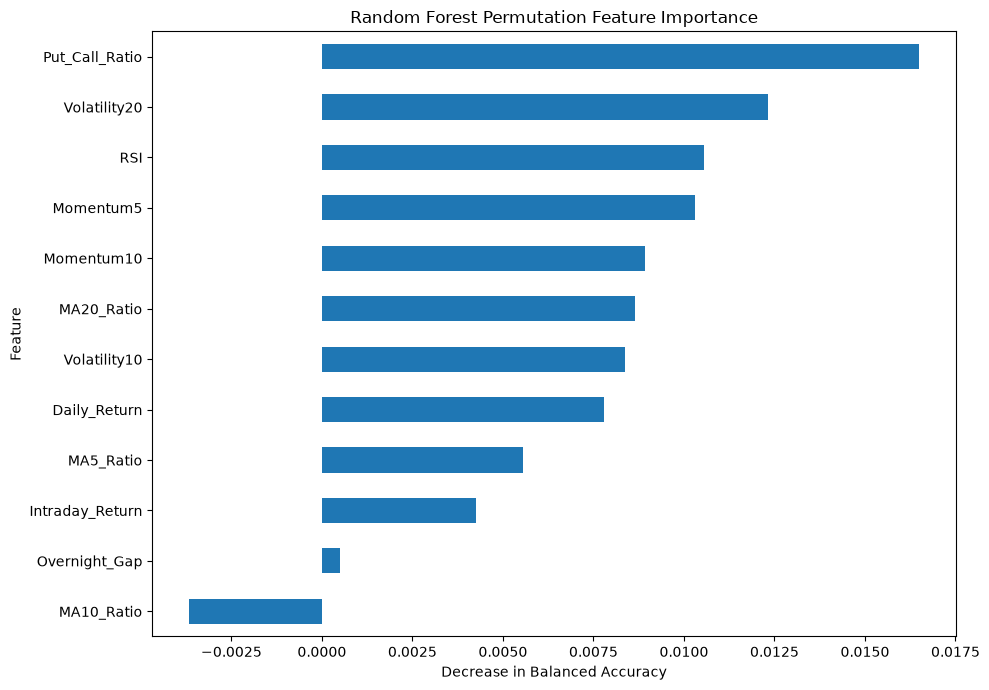

In [37]:
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit

# Our current preferred feature configuration
selected_features = (
    base_features
    + ["Overnight_Gap", "Intraday_Return"]
)

X_importance = (
    df_clv_test[selected_features]
    .iloc[:split_clv]
    .reset_index(drop=True)
)

y_importance = (
    df_clv_test["Target"]
    .iloc[:split_clv]
    .astype(int)
    .reset_index(drop=True)
)

tscv = TimeSeriesSplit(n_splits=5)

importance_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_importance), start=1
):

    model = clone(rf_model)

    model.fit(
        X_importance.iloc[train_idx],
        y_importance.iloc[train_idx]
    )

    # Calculate permutation importance on validation data
    importance = permutation_importance(
        model,
        X_importance.iloc[val_idx],
        y_importance.iloc[val_idx],
        scoring="balanced_accuracy",
        n_repeats=10,
        random_state=42,
        n_jobs=-1
    )

    fold_df = pd.DataFrame({
        "Feature": selected_features,
        "Importance": importance.importances_mean
    })

    fold_df["Fold"] = fold

    importance_results.append(fold_df)


# Combine results across folds
importance_df = pd.concat(
    importance_results,
    ignore_index=True
)

# Average importance across folds
feature_importance = (
    importance_df
    .groupby("Feature")["Importance"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)

feature_importance.columns = [
    "Mean Importance",
    "Importance Std"
]

display(
    feature_importance.style.format("{:.5f}")
)

# Visualize importance
feature_importance["Mean Importance"].sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    title="Random Forest Permutation Feature Importance"
)

plt.xlabel("Decrease in Balanced Accuracy")
plt.tight_layout()
plt.show()

In [38]:
# Current 12-feature configuration
current_features = selected_features.copy()

# Remove features with low permutation importance
reduced_features = [
    f for f in current_features
    if f not in ["Overnight_Gap"]
]

reduced_features_2 = [
    f for f in reduced_features
    if f not in ["MA10_Ratio"]
]

# Select the top 8 features by permutation importance
top_8_features = [
    "Put_Call_Ratio",
    "Volatility20",
    "RSI",
    "Momentum5",
    "Momentum10",
    "MA20_Ratio",
    "Volatility10",
    "Daily_Return"
]

# Configurations
reduced_feature_groups = {
    "Current 12 Features": current_features,
    "Remove Overnight Gap": reduced_features,
    "Remove Gap + MA10 Ratio": reduced_features_2,
    "Top 8 Features": top_8_features
}

# Target
y_reduced = (
    df_clv_test["Target"]
    .astype(int)
    .reset_index(drop=True)
)

tscv_reduced = TimeSeriesSplit(n_splits=5)

reduced_results = []

for name, columns in reduced_feature_groups.items():

    X_current = (
        df_clv_test[columns]
        .iloc[:split_clv]
        .reset_index(drop=True)
    )

    fold_metrics = []

    for train_idx, val_idx in tscv_reduced.split(X_current):

        model = clone(rf_model)

        model.fit(
            X_current.iloc[train_idx],
            y_reduced.iloc[train_idx]
        )

        predictions = model.predict(
            X_current.iloc[val_idx]
        )

        actual = y_reduced.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "F1": f1_score(
                actual, predictions,
                zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    reduced_results.append({
        "Feature Set": name,
        "Feature Count": len(columns),
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })

reduced_results_df = pd.DataFrame(reduced_results)

display(
    reduced_results_df
    .sort_values("Mean Accuracy", ascending=False)
    .set_index("Feature Set")
    .style.format("{:.4f}")
)

,Feature Count,Mean Accuracy,Balanced Accuracy,Mean F1,Accuracy Std
Feature Set,,,,,
Current 12 Features,12.0000,0.5314,0.5145,0.6220,0.0171
Remove Overnight Gap,11.0000,0.5271,0.5100,0.6107,0.0293
Remove Gap + MA10 Ratio,10.0000,0.5254,0.5092,0.6101,0.0339
Top 8 Features,8.0000,0.5220,0.5047,0.6040,0.0337


### 7.2 Random Forest hyperparameter tuning

Search a bounded set of Random Forest settings using training-only time-series cross-validation.

In [39]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Our preferred 12-feature configuration
final_candidate_features = (
    base_features
    + ["Overnight_Gap", "Intraday_Return"]
)

X_tuning = (
    df_clv_test[final_candidate_features]
    .iloc[:split_clv]
    .reset_index(drop=True)
)

y_tuning = (
    df_clv_test["Target"]
    .iloc[:split_clv]
    .astype(int)
    .reset_index(drop=True)
)


# Random Forest parameter search
rf_parameter_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [5, 10, 15, 20],
    "min_samples_leaf": [2, 5, 10, 15],
    "max_features": ["sqrt", 0.7, 0.9],
    "class_weight": ["balanced", "balanced_subsample"]
}


# Create randomized search
rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=rf_parameter_grid,
    n_iter=30,
    scoring="balanced_accuracy",
    cv=TimeSeriesSplit(n_splits=5),
    random_state=42,
    n_jobs=-1,
    verbose=1
)


# Run optimization
rf_random_search.fit(X_tuning, y_tuning)


# Display results
print("Best parameters:")
print(rf_random_search.best_params_)

print("\nBest cross-validation balanced accuracy:")
print(round(rf_random_search.best_score_, 4))

print("\nBest model:")
best_rf_model = rf_random_search.best_estimator_

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters:
{'n_estimators': 300, 'min_samples_split': 20, 'min_samples_leaf': 5, 'max_features': 0.7, 'max_depth': 10, 'class_weight': 'balanced_subsample'}

Best cross-validation balanced accuracy:
0.5187

Best model:


In [40]:
# Prepare holdout data
X_test_tuning = (
    df_clv_test[final_candidate_features]
    .iloc[split_clv:]
)

y_test_tuning = (
    df_clv_test["Target"]
    .iloc[split_clv:]
    .astype(int)
)


# 1. Original Random Forest
original_rf = clone(rf_model)

original_rf.fit(X_tuning, y_tuning)

original_predictions = original_rf.predict(
    X_test_tuning
)


# 2. Tuned Random Forest
# best_rf_model was already refitted by RandomizedSearchCV
tuned_predictions = best_rf_model.predict(
    X_test_tuning
)


# 3. Always-UP baseline
always_up_predictions = np.ones(
    len(y_test_tuning),
    dtype=int
)


# Compare results
evaluation_results = []

prediction_sets = {
    "Original Random Forest": original_predictions,
    "Tuned Random Forest": tuned_predictions,
    "Always-UP Baseline": always_up_predictions
}

for name, predictions in prediction_sets.items():

    metrics = calculate_metrics(
        y_test_tuning,
        predictions
    )

    evaluation_results.append({
        "Model": name,
        **metrics,
        "UP Predictions (%)": (
            np.mean(predictions) * 100
        )
    })

    print(f"\n{name}")
    print(confusion_matrix(y_test_tuning, predictions))


evaluation_df = pd.DataFrame(
    evaluation_results
).set_index("Model")

print("\nFINAL HOLDOUT COMPARISON")

display(
    evaluation_df.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "UP Predictions (%)": "{:.2f}%"
    })
)


Original Random Forest
[[ 25 140]
 [ 26 163]]

Tuned Random Forest
[[ 26 139]
 [ 32 157]]

Always-UP Baseline
[[  0 165]
 [  0 189]]

FINAL HOLDOUT COMPARISON


,Accuracy,Balanced Accuracy,Precision,Recall,F1,UP Predictions (%)
Model,,,,,,
Original Random Forest,0.5311,0.5070,0.5380,0.8624,0.6626,85.59%
Tuned Random Forest,0.5169,0.4941,0.5304,0.8307,0.6474,83.62%
Always-UP Baseline,0.5339,0.5000,0.5339,1.0000,0.6961,100.00%


## 8. Final algorithm comparison

### 8.1 Cross-validation comparison

Compare Logistic Regression, Random Forest, and SVM using the selected 12-feature candidate.

In [41]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

# Our preferred 12 features
final_candidate_features = (
    base_features
    + ["Overnight_Gap", "Intraday_Return"]
)

X_algorithm = (
    df_clv_test[final_candidate_features]
    .iloc[:split_clv]
    .reset_index(drop=True)
)

y_algorithm = (
    df_clv_test["Target"]
    .iloc[:split_clv]
    .astype(int)
    .reset_index(drop=True)
)

# Define models
comparison_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale",
            class_weight="balanced"
        ))
    ])
}

# Five chronological folds
tscv = TimeSeriesSplit(n_splits=5)

algorithm_results = []

for model_name, model in comparison_models.items():

    fold_metrics = []

    for train_idx, val_idx in tscv.split(X_algorithm):

        fold_model = clone(model)

        fold_model.fit(
            X_algorithm.iloc[train_idx],
            y_algorithm.iloc[train_idx]
        )

        predictions = fold_model.predict(
            X_algorithm.iloc[val_idx]
        )

        actual = y_algorithm.iloc[val_idx]

        fold_metrics.append({
            "Accuracy": accuracy_score(actual, predictions),
            "Balanced Accuracy": balanced_accuracy_score(
                actual, predictions
            ),
            "Precision": precision_score(
                actual, predictions, zero_division=0
            ),
            "Recall": recall_score(
                actual, predictions, zero_division=0
            ),
            "F1": f1_score(
                actual, predictions, zero_division=0
            )
        })

    fold_df = pd.DataFrame(fold_metrics)

    algorithm_results.append({
        "Model": model_name,
        "Mean Accuracy": fold_df["Accuracy"].mean(),
        "Balanced Accuracy": fold_df["Balanced Accuracy"].mean(),
        "Precision": fold_df["Precision"].mean(),
        "Recall": fold_df["Recall"].mean(),
        "Mean F1": fold_df["F1"].mean(),
        "Accuracy Std": fold_df["Accuracy"].std()
    })

algorithm_results_df = pd.DataFrame(algorithm_results)

display(
    algorithm_results_df
    .sort_values("Balanced Accuracy", ascending=False)
    .set_index("Model")
    .style.format("{:.4f}")
)

# Always-UP baseline on identical validation folds
baseline_scores = []

for _, val_idx in tscv.split(X_algorithm):

    actual = y_algorithm.iloc[val_idx]
    predictions = np.ones(len(val_idx), dtype=int)

    baseline_scores.append(
        accuracy_score(actual, predictions)
    )

print(
    "\nAlways-UP CV baseline:",
    round(np.mean(baseline_scores), 4)
)

,Mean Accuracy,Balanced Accuracy,Precision,Recall,Mean F1,Accuracy Std
Model,,,,,,
Random Forest,0.5314,0.5145,0.5433,0.7320,0.6220,0.0171
SVM,0.5186,0.5005,0.5329,0.7551,0.6218,0.0252
Logistic Regression,0.5059,0.4961,0.5286,0.6744,0.5897,0.0171



Always-UP CV baseline: 0.5322


In [42]:
# Prepare training and testing data
X_train_final = (
    df_clv_test[final_candidate_features]
    .iloc[:split_clv]
)

X_test_final = (
    df_clv_test[final_candidate_features]
    .iloc[split_clv:]
)

y_train_final = (
    df_clv_test["Target"]
    .iloc[:split_clv]
    .astype(int)
)

y_test_final = (
    df_clv_test["Target"]
    .iloc[split_clv:]
    .astype(int)
)


# Train and evaluate each algorithm
final_algorithm_results = []
final_fitted_models = {}

for model_name, model in comparison_models.items():

    fitted_model = clone(model)

    # Train using historical training data
    fitted_model.fit(
        X_train_final,
        y_train_final
    )

    # Predict the testing period
    predictions = fitted_model.predict(
        X_test_final
    )

    # Calculate metrics
    metrics = calculate_metrics(
        y_test_final,
        predictions
    )

    final_algorithm_results.append({
        "Model": model_name,
        **metrics,
        "UP Predictions (%)": (
            np.mean(predictions) * 100
        )
    })

    final_fitted_models[model_name] = fitted_model

    print(f"\n{model_name}")
    print(confusion_matrix(y_test_final, predictions))


# Always-UP baseline
always_up = np.ones(len(y_test_final), dtype=int)

final_algorithm_results.append({
    "Model": "Always-UP Baseline",
    **calculate_metrics(y_test_final, always_up),
    "UP Predictions (%)": 100.0
})


# Display comparison
final_algorithm_df = pd.DataFrame(
    final_algorithm_results
).set_index("Model")

display(
    final_algorithm_df.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}",
        "UP Predictions (%)": "{:.2f}%"
    })
)


Logistic Regression
[[ 40 125]
 [ 50 139]]

Random Forest
[[ 25 140]
 [ 26 163]]

SVM
[[ 35 130]
 [ 44 145]]


,Accuracy,Balanced Accuracy,Precision,Recall,F1,UP Predictions (%)
Model,,,,,,
Logistic Regression,0.5056,0.4889,0.5265,0.7354,0.6137,74.58%
Random Forest,0.5311,0.5070,0.5380,0.8624,0.6626,85.59%
SVM,0.5085,0.4897,0.5273,0.7672,0.6250,77.68%
Always-UP Baseline,0.5339,0.5000,0.5339,1.0000,0.6961,100.00%


## 9. Prediction threshold and class-weight experiments

### 9.1 Threshold sensitivity and directional metrics

Use out-of-fold probabilities to inspect the classification threshold and the trade-off between identifying UP and DOWN sessions.

In [43]:
# Prepare training data using our preferred 12 features
X_threshold = (
    df_clv_test[final_candidate_features]
    .iloc[:split_clv]
    .reset_index(drop=True)
)

y_threshold = (
    df_clv_test["Target"]
    .iloc[:split_clv]
    .astype(int)
    .reset_index(drop=True)
)

# Generate probabilities using chronological folds
tscv = TimeSeriesSplit(n_splits=5)

oof_actual = []
oof_probabilities = []

for train_idx, val_idx in tscv.split(X_threshold):

    model = clone(rf_model)

    model.fit(
        X_threshold.iloc[train_idx],
        y_threshold.iloc[train_idx]
    )

    probabilities = model.predict_proba(
        X_threshold.iloc[val_idx]
    )[:, 1]

    oof_probabilities.extend(probabilities)
    oof_actual.extend(y_threshold.iloc[val_idx])

oof_actual = np.array(oof_actual)
oof_probabilities = np.array(oof_probabilities)

print("Out-of-fold observations:", len(oof_actual))
print("Mean predicted UP probability:", round(
    oof_probabilities.mean(), 4
))

Out-of-fold observations: 1180
Mean predicted UP probability: 0.5264


In [44]:
# Test different prediction thresholds
threshold_results = []

thresholds = np.arange(0.40, 0.76, 0.01)

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        oof_actual,
        predictions,
        labels=[0, 1]
    ).ravel()

    metrics = calculate_metrics(
        oof_actual,
        predictions
    )

    # Calculate percentage of DOWN predictions
    down_predictions = np.mean(predictions == 0) * 100

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": metrics["Accuracy"],
        "Balanced Accuracy": metrics["Balanced Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
        "DOWN Predictions (%)": down_predictions,
        "Correct DOWN Predictions": tn
    })


threshold_results_df = pd.DataFrame(threshold_results)

# Display the best thresholds by balanced accuracy
print("TOP 15 THRESHOLDS")

display(
    threshold_results_df
    .sort_values("Balanced Accuracy", ascending=False)
    .head(15)
    .set_index("Threshold")
    .style.format("{:.4f}")
)


# Compare standard threshold against the best threshold
best_threshold = threshold_results_df.loc[
    threshold_results_df["Balanced Accuracy"].idxmax()
]

standard_threshold = threshold_results_df[
    np.isclose(threshold_results_df["Threshold"], 0.50)
].iloc[0]

print("\nSTANDARD THRESHOLD (0.50)")
display(standard_threshold.to_frame("Value"))

print("\nBEST BALANCED ACCURACY THRESHOLD")
display(best_threshold.to_frame("Value"))

print("\nSelected threshold:", round(best_threshold["Threshold"], 2))

TOP 15 THRESHOLDS


,Accuracy,Balanced Accuracy,Precision,Recall,F1,DOWN Predictions (%),Correct DOWN Predictions
Threshold,,,,,,,
0.500000,0.5314,0.5174,0.5443,0.7341,0.6251,28.2203,166.0000
0.510000,0.5254,0.5157,0.5442,0.6672,0.5994,34.7458,201.0000
0.490000,0.5288,0.5117,0.5398,0.7771,0.6371,23.3898,136.0000
0.480000,0.5288,0.5090,0.5377,0.8169,0.6485,19.1525,111.0000
0.640000,0.4797,0.5084,0.6094,0.0621,0.1127,94.5763,527.0000
0.600000,0.4839,0.5075,0.5597,0.1417,0.2262,86.5254,482.0000
0.620000,0.4805,0.5072,0.5743,0.0924,0.1591,91.4407,509.0000
0.610000,0.4814,0.5069,0.5656,0.1099,0.1840,89.6610,499.0000
0.420000,0.5339,0.5067,0.5358,0.9283,0.6795,7.7966,47.0000



STANDARD THRESHOLD (0.50)


,Value
Threshold,0.500000
Accuracy,0.531356
Balanced Accuracy,0.517401
Precision,0.544274
Recall,0.734076
F1,0.625085
DOWN Predictions (%),28.220339
Correct DOWN Predictions,166.000000



BEST BALANCED ACCURACY THRESHOLD


,Value
Threshold,0.500000
Accuracy,0.531356
Balanced Accuracy,0.517401
Precision,0.544274
Recall,0.734076
F1,0.625085
DOWN Predictions (%),28.220339
Correct DOWN Predictions,166.000000



Selected threshold: 0.5


In [45]:
# Compare thresholds using both UP and DOWN metrics

direction_results = []

for threshold in [0.48, 0.50, 0.51, 0.52, 0.55, 0.60]:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        oof_actual,
        predictions,
        labels=[0, 1]
    ).ravel()

    # DOWN-specific metrics
    down_precision = tn / (tn + fn) if (tn + fn) else 0
    down_recall = tn / (tn + fp) if (tn + fp) else 0

    # UP-specific metrics
    up_precision = tp / (tp + fp) if (tp + fp) else 0
    up_recall = tp / (tp + fn) if (tp + fn) else 0

    direction_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(oof_actual, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            oof_actual, predictions
        ),
        "DOWN Precision": down_precision,
        "DOWN Recall": down_recall,
        "UP Precision": up_precision,
        "UP Recall": up_recall,
        "DOWN Predictions": np.sum(predictions == 0)
    })


direction_df = pd.DataFrame(direction_results)

display(
    direction_df
    .set_index("Threshold")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions
Threshold,,,,,,,
0.480000,0.5288,0.5090,0.4912,0.2011,0.5377,0.8169,226.0000
0.500000,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,333.0000
0.510000,0.5254,0.5157,0.4902,0.3641,0.5442,0.6672,410.0000
0.520000,0.5093,0.5043,0.4728,0.4257,0.5359,0.5828,497.0000
0.550000,0.4822,0.4916,0.4613,0.6377,0.5204,0.3455,763.0000
0.600000,0.4839,0.5075,0.4721,0.8732,0.5597,0.1417,1021.0000


### 9.2 Initial class-weight comparison

This earlier comparison uses the expanded training feature matrix defined in the initial model section.

In [46]:
# Compare Random Forest class-weight settings using time-series CV

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
import numpy as np
import pandas as pd

class_weights = {
    "None": None,
    "Balanced": "balanced",
    "Balanced Subsample": "balanced_subsample"
}

tscv = TimeSeriesSplit(n_splits=5)

weight_results = []

X_cv = X_train.reset_index(drop=True)
y_cv = np.asarray(y_train).ravel()

for weight_name, weight_value in class_weights.items():

    all_actual = []
    all_predictions = []

    for train_idx, val_idx in tscv.split(X_cv):

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight=weight_value,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_cv.iloc[train_idx],
            y_cv[train_idx]
        )

        predictions = model.predict(X_cv.iloc[val_idx])

        all_actual.extend(y_cv[val_idx])
        all_predictions.extend(predictions)

    tn, fp, fn, tp = confusion_matrix(
        all_actual,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    weight_results.append({
        "Class Weight": weight_name,
        "Accuracy": accuracy_score(all_actual, all_predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            all_actual, all_predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": np.mean(
            np.array(all_predictions) == 0
        ) * 100
    })

weight_df = pd.DataFrame(weight_results)

display(
    weight_df
    .set_index("Class Weight")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Class Weight,,,,,,,
None,0.5297,0.5088,0.4949,0.1754,0.5366,0.8421,16.6102
Balanced,0.5178,0.5067,0.4789,0.3291,0.5363,0.6842,32.2034
Balanced Subsample,0.5136,0.5014,0.4709,0.3074,0.5324,0.6954,30.5932


### 9.3 Class weighting on the selected 12-feature candidate

Compare no class weighting, balanced weighting, and balanced-subsample weighting on the selected feature configuration.

In [47]:
# Compare Random Forest class-weight settings

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Use our preferred 12 features and training observations only
X_weight = (
    df_clv_test[final_candidate_features]
    .iloc[:split_clv]
    .reset_index(drop=True)
)

y_weight = (
    df_clv_test["Target"]
    .iloc[:split_clv]
    .astype(int)
    .reset_index(drop=True)
)

# Three class-weight configurations
class_weights = {
    "No Weighting": None,
    "Balanced": "balanced",
    "Balanced Subsample": "balanced_subsample"
}

tscv = TimeSeriesSplit(n_splits=5)

weight_results = []

for weight_name, weight_value in class_weights.items():

    all_actual = []
    all_predictions = []

    for train_idx, val_idx in tscv.split(X_weight):

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight=weight_value,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_weight.iloc[train_idx],
            y_weight.iloc[train_idx]
        )

        # Use the same 0.50 threshold as our previous experiment
        probabilities = model.predict_proba(
            X_weight.iloc[val_idx]
        )[:, 1]

        predictions = (
            probabilities >= 0.50
        ).astype(int)

        all_actual.extend(y_weight.iloc[val_idx])
        all_predictions.extend(predictions)

    # Calculate confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        all_actual,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    # Store results
    weight_results.append({
        "Class Weight": weight_name,
        "Accuracy": accuracy_score(
            all_actual, all_predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            all_actual, all_predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": (
            np.mean(np.array(all_predictions) == 0) * 100
        )
    })

# Display comparison
weight_results_df = pd.DataFrame(weight_results)

display(
    weight_results_df
    .set_index("Class Weight")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Class Weight,,,,,,,
No Weighting,0.5246,0.4996,0.4662,0.1123,0.5320,0.8869,11.2712
Balanced,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,28.2203
Balanced Subsample,0.5220,0.5058,0.4795,0.2536,0.5360,0.7580,24.7458


### 9.4 Stronger weighting for DOWN sessions

Test whether increasing the relative cost of missing DOWN sessions improves balanced performance or simply shifts predictions toward DOWN.

In [48]:
# Test stronger weighting for the DOWN class

custom_weights = {
    "Balanced": "balanced",
    "DOWN 1.25x": {0: 1.25, 1: 1.0},
    "DOWN 1.5x": {0: 1.5, 1: 1.0},
    "DOWN 2.0x": {0: 2.0, 1: 1.0},
    "DOWN 2.5x": {0: 2.5, 1: 1.0}
}

tscv = TimeSeriesSplit(n_splits=5)
custom_weight_results = []

for weight_name, weight_value in custom_weights.items():

    all_actual = []
    all_predictions = []

    for train_idx, val_idx in tscv.split(X_weight):

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight=weight_value,
            random_state=42,
            n_jobs=-1
        )

        model.fit(
            X_weight.iloc[train_idx],
            y_weight.iloc[train_idx]
        )

        probabilities = model.predict_proba(
            X_weight.iloc[val_idx]
        )[:, 1]

        predictions = (probabilities >= 0.50).astype(int)

        all_actual.extend(y_weight.iloc[val_idx])
        all_predictions.extend(predictions)

    tn, fp, fn, tp = confusion_matrix(
        all_actual,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    custom_weight_results.append({
        "Class Weight": weight_name,
        "Accuracy": accuracy_score(all_actual, all_predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            all_actual, all_predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": np.mean(
            np.array(all_predictions) == 0
        ) * 100
    })

custom_weight_df = pd.DataFrame(custom_weight_results)

display(
    custom_weight_df
    .set_index("Class Weight")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Class Weight,,,,,,,
Balanced,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,28.2203
DOWN 1.25x,0.5034,0.4920,0.4555,0.3152,0.5263,0.6688,32.3729
DOWN 1.5x,0.4898,0.4979,0.4661,0.6232,0.5294,0.3726,62.5424
DOWN 2.0x,0.4831,0.5048,0.4706,0.8424,0.5469,0.1672,83.7288
DOWN 2.5x,0.4898,0.5163,0.4767,0.9275,0.6226,0.1051,91.0169


## 10. Alternative tree ensembles

### 10.1 Extra Trees and gradient-boosting comparisons

Compare the selected Random Forest against Extra Trees, Gradient Boosting, and Histogram Gradient Boosting.

In [49]:
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Compare two tree-based models
tree_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

tscv = TimeSeriesSplit(n_splits=5)
tree_results = []

for model_name, model in tree_models.items():

    all_actual = []
    all_predictions = []

    for train_idx, val_idx in tscv.split(X_weight):

        model.fit(
            X_weight.iloc[train_idx],
            y_weight.iloc[train_idx]
        )

        predictions = model.predict(
            X_weight.iloc[val_idx]
        )

        all_actual.extend(y_weight.iloc[val_idx])
        all_predictions.extend(predictions)

    tn, fp, fn, tp = confusion_matrix(
        all_actual,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    tree_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            all_actual, all_predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            all_actual, all_predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": np.mean(
            np.array(all_predictions) == 0
        ) * 100
    })

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df
    .set_index("Model")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Model,,,,,,,
Random Forest,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,28.2203
Extra Trees,0.5195,0.5027,0.4735,0.2428,0.5340,0.7627,23.9831


In [50]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Define the two models
models_to_compare = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    )
}

tscv = TimeSeriesSplit(n_splits=5)
boosting_results = []

for model_name, model in models_to_compare.items():

    all_actual = []
    all_predictions = []

    for train_idx, val_idx in tscv.split(X_weight):

        X_fold_train = X_weight.iloc[train_idx]
        y_fold_train = y_weight.iloc[train_idx]

        X_fold_val = X_weight.iloc[val_idx]
        y_fold_val = y_weight.iloc[val_idx]

        # Train with balanced class weighting
        if model_name == "Gradient Boosting":

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            model.fit(
                X_fold_train,
                y_fold_train,
                sample_weight=sample_weights
            )

        else:
            model.fit(
                X_fold_train,
                y_fold_train
            )

        predictions = model.predict(X_fold_val)

        all_actual.extend(y_fold_val)
        all_predictions.extend(predictions)

    tn, fp, fn, tp = confusion_matrix(
        all_actual,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    boosting_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            all_actual, all_predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            all_actual, all_predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": np.mean(
            np.array(all_predictions) == 0
        ) * 100
    })

boosting_results_df = pd.DataFrame(boosting_results)

display(
    boosting_results_df
    .set_index("Model")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Model,,,,,,,
Random Forest,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,28.2203
Gradient Boosting,0.5169,0.5093,0.4800,0.3913,0.5397,0.6274,38.1356


In [51]:
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Define models
models_to_compare = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    ),

    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    )
}

tscv = TimeSeriesSplit(n_splits=5)
hist_results = []

for model_name, model in models_to_compare.items():

    all_actual = []
    all_predictions = []

    for train_idx, val_idx in tscv.split(X_weight):

        X_fold_train = X_weight.iloc[train_idx]
        y_fold_train = y_weight.iloc[train_idx]

        X_fold_val = X_weight.iloc[val_idx]
        y_fold_val = y_weight.iloc[val_idx]

        if model_name in [
            "Gradient Boosting",
            "Histogram Gradient Boosting"
        ]:

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            model.fit(
                X_fold_train,
                y_fold_train,
                sample_weight=sample_weights
            )

        else:
            model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        all_actual.extend(y_fold_val)
        all_predictions.extend(predictions)

    tn, fp, fn, tp = confusion_matrix(
        all_actual,
        all_predictions,
        labels=[0, 1]
    ).ravel()

    hist_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            all_actual, all_predictions
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            all_actual, all_predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": np.mean(
            np.array(all_predictions) == 0
        ) * 100
    })

hist_results_df = pd.DataFrame(hist_results)

display(
    hist_results_df
    .set_index("Model")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Model,,,,,,,
Random Forest,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,28.2203
Gradient Boosting,0.5169,0.5093,0.4800,0.3913,0.5397,0.6274,38.1356
Histogram Gradient Boosting,0.5093,0.5020,0.4703,0.3877,0.5338,0.6162,38.5593


### 10.2 Fold-by-fold consistency

Inspect balanced accuracy in each validation period rather than relying only on the pooled average.

In [52]:
from sklearn.base import clone
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Define our three leading models
models_to_compare = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    ),

    "Histogram Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    )
}

tscv = TimeSeriesSplit(n_splits=5)
fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_weight), start=1
):

    X_fold_train = X_weight.iloc[train_idx]
    y_fold_train = y_weight.iloc[train_idx]

    X_fold_val = X_weight.iloc[val_idx]
    y_fold_val = y_weight.iloc[val_idx]

    # Always-UP baseline
    prediction = np.ones(len(val_idx), dtype=int)

    tn, fp, fn, tp = confusion_matrix(
        y_fold_val,
        prediction,
        labels=[0, 1]
    ).ravel()

    fold_results.append({
        "Fold": fold,
        "Model": "Always-UP Baseline",
        "Accuracy": accuracy_score(y_fold_val, prediction),
        "Balanced Accuracy": balanced_accuracy_score(
            y_fold_val, prediction
        ),
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0
    })

    # Test each model on this fold
    for model_name, model_template in models_to_compare.items():

        model = clone(model_template)

        # Apply balanced sample weights to boosting models
        if model_name in [
            "Gradient Boosting",
            "Histogram Gradient Boosting"
        ]:
            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            model.fit(
                X_fold_train,
                y_fold_train,
                sample_weight=sample_weights
            )
        else:
            model.fit(X_fold_train, y_fold_train)

        predictions = model.predict(X_fold_val)

        tn, fp, fn, tp = confusion_matrix(
            y_fold_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        fold_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_fold_val, predictions
            ),
            "Balanced Accuracy": balanced_accuracy_score(
                y_fold_val, predictions
            ),
            "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
            "UP Recall": tp / (tp + fn) if (tp + fn) else 0
        })

fold_results_df = pd.DataFrame(fold_results)

# Show performance in each individual period
print("PERFORMANCE BY FOLD")

display(
    fold_results_df
    .pivot(
        index="Fold",
        columns="Model",
        values="Balanced Accuracy"
    )
    .style.format("{:.4f}")
)

# Summarize average performance and variation
print("\nAVERAGE PERFORMANCE ACROSS FIVE FOLDS")

fold_summary = (
    fold_results_df
    .groupby("Model")
    .agg({
        "Accuracy": ["mean", "std"],
        "Balanced Accuracy": ["mean", "std"],
        "DOWN Recall": ["mean", "std"],
        "UP Recall": ["mean", "std"]
    })
)

display(fold_summary.style.format("{:.4f}"))

PERFORMANCE BY FOLD


Model,Always-UP Baseline,Gradient Boosting,Histogram Gradient Boosting,Random Forest
Fold,,,,
1,0.5000,0.5217,0.4883,0.5246
2,0.5000,0.5300,0.5087,0.5347
3,0.5000,0.4909,0.5155,0.5124
4,0.5000,0.4674,0.4869,0.4894
5,0.5000,0.5001,0.4916,0.5112



AVERAGE PERFORMANCE ACROSS FIVE FOLDS


### 10.3 Random Forest and Gradient Boosting ensemble

Average the two models’ predicted UP probabilities and compare the ensemble with each individual model.

In [53]:
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix
)

# Define both models
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    min_samples_split=10,
    min_samples_leaf=5,
    subsample=0.8,
    random_state=42
)

# Generate out-of-fold probabilities
tscv = TimeSeriesSplit(n_splits=5)

oof_actual = []
rf_probabilities = []
gb_probabilities = []

for train_idx, val_idx in tscv.split(X_weight):

    X_train_fold = X_weight.iloc[train_idx]
    y_train_fold = y_weight.iloc[train_idx]

    X_val_fold = X_weight.iloc[val_idx]
    y_val_fold = y_weight.iloc[val_idx]

    # Train Random Forest
    rf_model.fit(
        X_train_fold,
        y_train_fold
    )

    # Train Gradient Boosting with balanced sample weights
    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_fold
    )

    gb_model.fit(
        X_train_fold,
        y_train_fold,
        sample_weight=sample_weights
    )

    # Get UP probabilities
    rf_probabilities.extend(
        rf_model.predict_proba(X_val_fold)[:, 1]
    )

    gb_probabilities.extend(
        gb_model.predict_proba(X_val_fold)[:, 1]
    )

    oof_actual.extend(y_val_fold)

# Convert to arrays
oof_actual = np.array(oof_actual)
rf_probabilities = np.array(rf_probabilities)
gb_probabilities = np.array(gb_probabilities)

# Average the model probabilities
ensemble_probabilities = (
    rf_probabilities + gb_probabilities
) / 2

# Compare predictions
prediction_sets = {
    "Random Forest": (rf_probabilities >= 0.50).astype(int),
    "Gradient Boosting": (gb_probabilities >= 0.50).astype(int),
    "50/50 Ensemble": (ensemble_probabilities >= 0.50).astype(int),
    "Always-UP Baseline": np.ones(len(oof_actual), dtype=int)
}

ensemble_results = []

for model_name, predictions in prediction_sets.items():

    tn, fp, fn, tp = confusion_matrix(
        oof_actual,
        predictions,
        labels=[0, 1]
    ).ravel()

    ensemble_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(oof_actual, predictions),
        "Balanced Accuracy": balanced_accuracy_score(
            oof_actual, predictions
        ),
        "DOWN Precision": tn / (tn + fn) if (tn + fn) else 0,
        "DOWN Recall": tn / (tn + fp) if (tn + fp) else 0,
        "UP Precision": tp / (tp + fp) if (tp + fp) else 0,
        "UP Recall": tp / (tp + fn) if (tp + fn) else 0,
        "DOWN Predictions (%)": np.mean(predictions == 0) * 100
    })

ensemble_results_df = pd.DataFrame(ensemble_results)

display(
    ensemble_results_df
    .set_index("Model")
    .style.format("{:.4f}")
)

,Accuracy,Balanced Accuracy,DOWN Precision,DOWN Recall,UP Precision,UP Recall,DOWN Predictions (%)
Model,,,,,,,
Random Forest,0.5314,0.5174,0.4985,0.3007,0.5443,0.7341,28.2203
Gradient Boosting,0.5169,0.5093,0.4800,0.3913,0.5397,0.6274,38.1356
50/50 Ensemble,0.5229,0.5120,0.4859,0.3424,0.5411,0.6815,32.9661
Always-UP Baseline,0.5322,0.5000,0.0000,0.0000,0.5322,1.0000,0.0000


## 11. Probability quality diagnostics

### 11.1 Initial out-of-fold probability comparison

Evaluate whether predicted probabilities carry useful information beyond a simple historical-prevalence estimate.

In [54]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)
from sklearn.utils.class_weight import compute_sample_weight

# Store out-of-fold probabilities
probability_results = {
    "Random Forest": [],
    "Gradient Boosting": [],
    "50/50 Ensemble": [],
    "Training Prevalence Baseline": []
}

probability_actual = []

tscv = TimeSeriesSplit(n_splits=5)

for train_idx, val_idx in tscv.split(X_weight):

    X_train_fold = X_weight.iloc[train_idx]
    y_train_fold = y_weight.iloc[train_idx]

    X_val_fold = X_weight.iloc[val_idx]
    y_val_fold = y_weight.iloc[val_idx]

    # Random Forest
    rf_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train_fold, y_train_fold)

    rf_probs = rf_model.predict_proba(X_val_fold)[:, 1]

    # Gradient Boosting
    gb_model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        min_samples_split=10,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    )

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train_fold
    )

    gb_model.fit(
        X_train_fold,
        y_train_fold,
        sample_weight=sample_weights
    )

    gb_probs = gb_model.predict_proba(X_val_fold)[:, 1]

    # Store probabilities
    probability_results["Random Forest"].extend(rf_probs)
    probability_results["Gradient Boosting"].extend(gb_probs)

    probability_results["50/50 Ensemble"].extend(
        (rf_probs + gb_probs) / 2
    )

    # Baseline: training fold's UP percentage
    probability_results["Training Prevalence Baseline"].extend(
        [y_train_fold.mean()] * len(val_idx)
    )

    probability_actual.extend(y_val_fold)

# Convert actual outcomes to an array
probability_actual = np.array(probability_actual)

# Evaluate probability quality
quality_results = []

for model_name, probabilities in probability_results.items():

    probabilities = np.clip(
        np.array(probabilities),
        1e-6,
        1 - 1e-6
    )

    quality_results.append({
        "Model": model_name,
        "ROC AUC": (
            roc_auc_score(probability_actual, probabilities)
            if model_name != "Training Prevalence Baseline"
            else np.nan
        ),
        "Average Precision": (
            average_precision_score(
                probability_actual, probabilities
            )
            if model_name != "Training Prevalence Baseline"
            else np.nan
        ),
        "Brier Score": brier_score_loss(
            probability_actual, probabilities
        ),
        "Log Loss": log_loss(
            probability_actual,
            probabilities,
            labels=[0, 1]
        )
    })

quality_df = pd.DataFrame(quality_results)

display(
    quality_df
    .set_index("Model")
    .style.format("{:.4f}")
)

,ROC AUC,Average Precision,Brier Score,Log Loss
Model,,,,
Random Forest,0.5017,0.5344,0.2536,0.7009
Gradient Boosting,0.5082,0.5351,0.2573,0.7094
50/50 Ensemble,0.5061,0.5359,0.2546,0.7032
Training Prevalence Baseline,nan,nan,0.2508,0.6948


### 11.2 Boundary-purged probability comparison

For this final diagnostic, remove the last training row in each fold because its shifted next-day target overlaps the first validation date. Compare weighted and unweighted Random Forest probabilities with the training-prevalence baseline.

In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)

# Compare weighted and unweighted Random Forest
rf_configurations = {
    "No Class Weight": None,
    "Balanced": "balanced"
}

tscv = TimeSeriesSplit(n_splits=5)

probability_comparison = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_weight), start=1
):

    # Purge the last training observation to avoid
    # using an outcome from the validation period
    train_idx = train_idx[:-1]

    X_train_fold = X_weight.iloc[train_idx]
    y_train_fold = y_weight.iloc[train_idx]

    X_val_fold = X_weight.iloc[val_idx]
    y_val_fold = y_weight.iloc[val_idx]

    # Historical UP frequency from training data
    prevalence = y_train_fold.mean()

    # Evaluate both Random Forest configurations
    for name, class_weight in rf_configurations.items():

        model = RandomForestClassifier(
            n_estimators=200,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight=class_weight,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train_fold, y_train_fold)

        probabilities = model.predict_proba(
            X_val_fold
        )[:, 1]

        probability_comparison.append({
            "Fold": fold,
            "Model": name,
            "ROC AUC": roc_auc_score(
                y_val_fold, probabilities
            ),
            "Average Precision": average_precision_score(
                y_val_fold, probabilities
            ),
            "Brier Score": brier_score_loss(
                y_val_fold, probabilities
            ),
            "Log Loss": log_loss(
                y_val_fold, probabilities
            )
        })

    # Historical-prevalence baseline
    baseline_probabilities = np.full(
        len(y_val_fold),
        prevalence
    )

    probability_comparison.append({
        "Fold": fold,
        "Model": "Prevalence Baseline",
        "ROC AUC": 0.5000,
        "Average Precision": average_precision_score(
            y_val_fold, baseline_probabilities
        ),
        "Brier Score": brier_score_loss(
            y_val_fold, baseline_probabilities
        ),
        "Log Loss": log_loss(
            y_val_fold, baseline_probabilities
        )
    })

# Create results table
probability_comparison_df = pd.DataFrame(
    probability_comparison
)

print("AVERAGE PERFORMANCE ACROSS FIVE FOLDS")

probability_summary = (
    probability_comparison_df
    .groupby("Model")
    .agg({
        "ROC AUC": ["mean", "std"],
        "Average Precision": ["mean", "std"],
        "Brier Score": ["mean", "std"],
        "Log Loss": ["mean", "std"]
    })
)

display(
    probability_summary.style.format("{:.4f}")
)

print("\nRESULTS BY INDIVIDUAL FOLD")

display(
    probability_comparison_df
    .set_index(["Fold", "Model"])
    .style.format("{:.4f}")
)

AVERAGE PERFORMANCE ACROSS FIVE FOLDS



RESULTS BY INDIVIDUAL FOLD


## 12. Summary and conclusions

### Main findings

- The selected experimental feature set contains **12 features**: the original nine technical indicators, `Put_Call_Ratio`, `Overnight_Gap`, and `Intraday_Return`.
- **Random Forest with `class_weight="balanced"`** was the strongest overall classification candidate among the tested algorithms. At the 0.50 threshold, its pooled out-of-fold results were approximately **53.14% accuracy** and **51.74% balanced accuracy**, with **30.07% DOWN recall** and **73.41% UP recall**.
- Stronger DOWN class weights increased DOWN recall but substantially reduced UP recall. Extra Trees, Gradient Boosting, Histogram Gradient Boosting, and the 50/50 ensemble did not outperform the selected Random Forest on balanced accuracy.
- The final boundary-purged probability diagnostic did **not** show a useful probability advantage over the training-prevalence baseline. The baseline had a lower Brier score and log loss, while model ROC AUC values remained close to 0.50.

### Current model decision

Retain the balanced Random Forest as the **leading experimental classifier**, not as a proven market-prediction system. The results indicate only a weak directional signal, with materially better recognition of UP sessions than DOWN sessions.

### Evaluation limitations and next steps

- The chronological 80/20 holdout was examined repeatedly during experimentation. It should not be described as an untouched final test set. A future, later date range should be reserved for a final evaluation.
- The boundary-purged probability diagnostic is the cleanest probability comparison in this notebook. Earlier experiments should be interpreted as exploratory comparisons, not as a single definitive estimate of future performance.
- Any future production or dashboard version should record predictions before outcomes are known, then evaluate them on genuinely new observations.

> **Overall conclusion:** The experimentation phase is complete. Keep the balanced Random Forest as the current benchmark and move on to documenting the project and designing the prediction workflow, while being transparent about the model’s limited predictive performance.